In [23]:
"""
🤖 TRABAJO FIN DE MÁSTER - BOT DE TRADING SAC
=============================================

Entrenamiento de un agente de trading usando Soft Actor-Critic (SAC)
para optimizar carteras de ETFs con reward shaping corregido.

Autor: [Tu nombre]
Tutor: [Nombre del tutor]
Fecha: Agosto 2025

FASES DEL PROYECTO:
- Fase 2: Reward base (baseline)
- Fase 3A: Sharpe ratio shaping (corregido)
- Fase 3C: Sharpe + Momentum shaping (corregido)

CORRECCIONES IMPLEMENTADAS:
✅ Shaping scale reducido (100.0 → 0.01)
✅ Momentum logarítmico suavizado
✅ Pesos balanceados 60/40 (Sharpe/Momentum)
✅ Evaluación sin shaping para validación objetiva
✅ Escalado de datos sin data leakage
"""

print("📚 TFM Trading Bot - Notebook Limpio")
print("🎯 Versión corregida según feedback del tutor")

📚 TFM Trading Bot - Notebook Limpio
🎯 Versión corregida según feedback del tutor


In [24]:
# ============================================================================
# CELDA 1: IMPORTS Y CONFIGURACIÓN INICIAL
# ============================================================================

import os
import logging
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Optional, Dict, Any, Tuple, List
from pathlib import Path
from dataclasses import dataclass, field
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Stable-Baselines3
from stable_baselines3 import SAC
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.logger import configure
from stable_baselines3.common.callbacks import CheckpointCallback, EvalCallback
from stable_baselines3.common.vec_env import DummyVecEnv, SubprocVecEnv
from stable_baselines3.common.utils import set_random_seed
from stable_baselines3.common.callbacks import BaseCallback
# Scikit-learn
from sklearn.preprocessing import StandardScaler

# Gym
import gymnasium as gym
from gymnasium import spaces


print("✅ Imports completados")
print(f"🔥 PyTorch version: {torch.__version__}")
print(f"🚀 GPU disponible: {'Sí' if torch.cuda.is_available() else 'No'}")


✅ Imports completados
🔥 PyTorch version: 2.7.1+cpu
🚀 GPU disponible: No


In [25]:
# ============================================================================
# CELDA 2: CONFIGURACIÓN Y UTILIDADES
# ============================================================================

@dataclass
class TradingConfig:
    """
    ⚙️ CONFIGURACIÓN CENTRALIZADA DEL PROYECTO
    ==========================================
    
    Todos los parámetros importantes en un solo lugar para fácil modificación.
    Incluye las correcciones basadas en feedback del tutor.
    """
    
    # 📁 DIRECTORIOS DE TRABAJO
    log_dir: str = "./logs_tensorboard/semillas/"
    checkpoint_dir: str = "./checkpoints/semillas/"
    models_dir: str = "./models/semillas/"
    
    # 🎯 PARÁMETROS DE ENTRENAMIENTO
    max_timesteps: int = 150000      # Timesteps por fase
    eval_freq: int = 10000           # Evaluaciones cada X pasos
    save_freq: int = 1000           # Guardar cada X pasos
    patience: int = 999                    # Evaluaciones sin mejora antes de parar
    min_improvement: float = 0.02        # Mejora mínima en Sharpe para continuar
    
    # 🧠 HIPERPARÁMETROS SAC
    learning_rate: float = 3e-4      # Recomendación del tutor
    buffer_size: int = 150000        # Tamaño del replay buffer
    batch_size: int = 256            # Tamaño del batch
    learning_starts: int = 1000      # Pasos antes de empezar a entrenar
    ent_coef: float = 0.1           # Coeficiente de entropía (exploración)
    
    # 💰 PARÁMETROS DE TRADING
    transaction_cost: float = 0.0001   # 0.01% comisión por operación
    
    # 🎯 REWARD SHAPING (CORREGIDO)
    shaping_scale: float = 1         # ✅ ERA 100.0 → AHORA 1
    base_reward_scale: float = 1.0      # Reward base sin modificar
    
    # ⚖️ PESOS PARA FASE 3C (60/40 según tutor)
    sharpe_weight: float = 0.6          # 60% peso para Sharpe
    momentum_weight: float = 0.4        # 40% peso para Momentum
    

    # 🚀 MOMENTUM MEJORADO
    momentum_window: int = 20           # Cambiar de 30 a 20
    momentum_threshold: float = 0.3     # Cambiar de 0.05 a 0.3 (para correlación)
    use_log_returns: bool = True        # Mantener
    use_tanh_smoothing: bool = False    # Cambiar de True a False
    debug_momentum: bool = False        # Mantener

    # SEMILLAS PARA VALIDACIÓN ROBUSTA
    random_seeds: List[int] = field(default_factory=lambda: [42, 123, 456])
    n_seeds: int = 3  # Cuántas semillas usar


def setup_directories(config: TradingConfig):
    """🗂️ Crear directorios necesarios"""
    directories = [config.log_dir, config.checkpoint_dir, config.models_dir]
    
    for directory in directories:
        Path(directory).mkdir(parents=True, exist_ok=True)
        print(f"📁 Directorio verificado: {directory}")


def detect_device() -> str:
    """🖥️ Detectar el mejor device disponible"""
    if torch.cuda.is_available():
        device_name = torch.cuda.get_device_name(0)
        print(f"🚀 GPU detectada: {device_name}")
        return "cuda"
    else:
        print("💻 Usando CPU")
        return "cpu"


# Crear configuración por defecto
config = TradingConfig()
device = detect_device()
setup_directories(config)

print("⚙️ Configuración creada exitosamente")
print(f"📊 Timesteps por entrenamiento: {config.max_timesteps:,}")
print(f"🎯 Shaping scale corregido: {config.shaping_scale}")
print(f"⚖️ Pesos 3C - Sharpe: {config.sharpe_weight}, Momentum: {config.momentum_weight}")

💻 Usando CPU
📁 Directorio verificado: ./logs_tensorboard/semillas/
📁 Directorio verificado: ./checkpoints/semillas/
📁 Directorio verificado: ./models/semillas/
⚙️ Configuración creada exitosamente
📊 Timesteps por entrenamiento: 150,000
🎯 Shaping scale corregido: 1
⚖️ Pesos 3C - Sharpe: 0.6, Momentum: 0.4


In [26]:
# ============================================================================
# CELDA 3: GESTIÓN DE DATOS SIN DATA LEAKAGE
# ============================================================================

class DataManager:
    """
    📊 GESTOR DE DATOS INTELIGENTE
    =============================
    
    Se encarga de:
    1. Cargar los datos del archivo
    2. Dividir en train/test/holdout temporalmente
    3. Escalar SOLO con datos de entrenamiento (evita data leakage)
    """
    
    def __init__(self, file_path: str):
        self.file_path = file_path
        self.raw_data = None
        self.scaler = None
        
        print(f"📂 DataManager inicializado para: {file_path}")
    
    def load_data(self) -> pd.DataFrame:
        """📥 Cargar datos del archivo"""
        
        try:
            if self.file_path.endswith('.xlsx'):
                self.raw_data = pd.read_excel(self.file_path)
                print("📊 Archivo Excel cargado")
            elif self.file_path.endswith('.csv'):
                self.raw_data = pd.read_csv(self.file_path)
                print("📊 Archivo CSV cargado")
            else:
                raise ValueError("❌ Formato no soportado. Usar .xlsx o .csv")
            
            # Preparar fechas
            self.raw_data['date'] = pd.to_datetime(self.raw_data['date'])
            self.raw_data.set_index('date', inplace=True)
            self.raw_data = self.raw_data.dropna()
            
            print(f"✅ Datos cargados: {len(self.raw_data)} filas, {len(self.raw_data.columns)} columnas")
            print(f"📅 Período: {self.raw_data.index.min()} a {self.raw_data.index.max()}")
            
            return self.raw_data
            
        except Exception as e:
            print(f"❌ Error cargando datos: {e}")
            return None
    
    def split_temporal(self) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
        """
        🔪 DIVISIÓN TEMPORAL DE DATOS
        ============================
        
        - Train: Hasta 2019 (para entrenar)
        - Test: 2020-2022 (para validar durante entrenamiento)  
        - Holdout: 2023+ (para evaluación final objetiva)
        """
        
        if self.raw_data is None:
            raise ValueError("❌ Primero debes cargar los datos con load_data()")
        
        # División temporal estricta
        train_data = self.raw_data.loc[:'2019-12-31'].copy()
        test_data = self.raw_data.loc['2020-01-01':'2022-12-31'].copy()
        holdout_data = self.raw_data.loc['2023-01-01':].copy()
        
        # Verificar tamaños
        print("🔪 División temporal completada:")
        print(f"   📈 Train (hasta 2019): {len(train_data):,} muestras")
        print(f"   📊 Test (2020-2022): {len(test_data):,} muestras")
        print(f"   🔒 Holdout (2023+): {len(holdout_data):,} muestras")
        
        # Verificar que hay datos suficientes
        min_samples = 100
        for name, data in [("Train", train_data), ("Test", test_data), ("Holdout", holdout_data)]:
            if len(data) < min_samples:
                print(f"⚠️ {name} tiene solo {len(data)} muestras (mínimo recomendado: {min_samples})")
        
        return train_data, test_data, holdout_data
    
    def scale_without_leakage(self, train_data: pd.DataFrame, test_data: pd.DataFrame, 
                            holdout_data: pd.DataFrame, etfs: List[str]):
        """
        🎯 ESCALADO SIN DATA LEAKAGE (CRÍTICO)
        =====================================
        
        REGLA DE ORO: El scaler solo "ve" datos de entrenamiento.
        Test y holdout usan las estadísticas del train, no las suyas.
        
        Esto evita que el modelo "haga trampa" conociendo el futuro.
        """
        
        print("🔧 Aplicando escalado StandardScaler SIN data leakage...")
        
        # Crear scaler (solo aprenderá de train)
        self.scaler = StandardScaler()
        
        # Copiar datos originales (para cálculos de precios)
        train_orig = train_data.copy()
        test_orig = test_data.copy()
        holdout_orig = holdout_data.copy()
        
        # Copiar para escalado (para observaciones del modelo)
        train_scaled = train_data.copy()
        test_scaled = test_data.copy()
        holdout_scaled = holdout_data.copy()
        
        # ✅ CORRECTO: Fit solo con datos de entrenamiento
        train_scaled[etfs] = self.scaler.fit_transform(train_data[etfs])
        
        # ✅ CORRECTO: Transform (NO fit) para test y holdout
        test_scaled[etfs] = self.scaler.transform(test_data[etfs])
        holdout_scaled[etfs] = self.scaler.transform(holdout_data[etfs])
        
        # Verificar que NO hay data leakage
        train_stats = train_scaled[etfs].describe()
        test_stats = test_scaled[etfs].describe()
        
        print("✅ Escalado completado sin data leakage")
        print(f"📊 Train escalado - Media: {train_stats.loc['mean'].mean():.3f}, Std: {train_stats.loc['std'].mean():.3f}")
        print(f"📊 Test escalado - Media: {test_stats.loc['mean'].mean():.3f}, Std: {test_stats.loc['std'].mean():.3f}")
        
        # VERIFICACIÓN CRÍTICA: Si test tiene media ≈ 0, hay data leakage
        if abs(test_stats.loc['mean'].mean()) < 0.1:
            print("⚠️ ADVERTENCIA: Test tiene media muy cerca de 0. ¿Posible data leakage?")
        else:
            print("✅ Test tiene media diferente de 0. No hay data leakage aparente.")
        
        return (train_orig, test_orig, holdout_orig,
                train_scaled, test_scaled, holdout_scaled)


print("📊 DataManager creado - Listo para gestionar datos")

📊 DataManager creado - Listo para gestionar datos


In [27]:
# ============================================================================
# CELDA 4: ENTORNO DE TRADING CORREGIDO
# ============================================================================

class FixedTradingEnv(gym.Env):
    """
    🏪 ENTORNO DE TRADING CON CORRECCIONES DEL TUTOR
    ===============================================
    
    Este entorno implementa todas las correcciones basadas en el feedback:
    1. Reward shaping con escala reducida (0.01 vs 100.0)
    2. Momentum logarítmico suavizado con tanh
    3. Separación entre modo entrenamiento (con shaping) y evaluación (sin shaping)
    4. Pesos balanceados 60/40 para Sharpe/Momentum
    """
    
    def __init__(self, datos_scaled: pd.DataFrame, datos_original: pd.DataFrame, 
                 etfs: List[str], config: TradingConfig, 
                 phase: str = "3A", mode: str = "train"):
        super().__init__()
        
        # 📊 DATOS
        self.datos_scaled = datos_scaled.dropna().copy()     # Para observaciones
        self.datos_original = datos_original.dropna().copy() # Para precios reales
        self.etfs = etfs
        self.n_assets = len(etfs)
        self.config = config
        
        # 🎯 CONFIGURACIÓN DE FASE
        self.phase = phase  # "3A" o "3C"
        self.mode = mode    # "train" o "eval"
        
        # Configurar pesos según la fase
        if phase == "3A":
            self.sharpe_weight = 1.0      # Solo Sharpe
            self.momentum_weight = 0.0
            print(f"🥈 Fase 3A: Solo Sharpe shaping")
        elif phase == "3C":
            self.sharpe_weight = config.sharpe_weight    # 0.6
            self.momentum_weight = config.momentum_weight # 0.4
            print(f"🥉 Fase 3C: Sharpe ({self.sharpe_weight}) + Momentum ({self.momentum_weight})")
        
        # 🎭 CONTROL DE REWARD SHAPING
        # CLAVE: Shaping solo durante entrenamiento, NO durante evaluación
        self.use_shaping = (mode == "train")
        print(f"🎭 Modo {mode} - Shaping: {'ON' if self.use_shaping else 'OFF'}")
        
        # 🏗️ CONFIGURACIÓN GYM
        self.action_space = spaces.Box(
            low=-1, high=1, shape=(self.n_assets,), dtype=np.float32
        )
        
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf, 
            shape=(self.datos_scaled.shape[1],), dtype=np.float32
        )
        
        # 📍 ESTADO DEL ENTORNO
        self.start_index = 60  # Empezar después de suficientes datos históricos
        self.current_step = self.start_index
        self.dates = self.datos_scaled.index.to_list()
        
        # 📊 TRACKING PARA ANÁLISIS
        self.episode_data = {
            'portfolio_returns': [],    # Returns de la cartera
            'base_rewards': [],         # Rewards sin shaping
            'shaping_rewards': [],      # Solo shaping
            'total_rewards': [],        # Suma de ambos
            'momentum_signals': [],     # Valores del momentum
            'momentum_activations': [], # Cuándo momentum está "activo"
            'sharpe_signals': [],       # Valores del Sharpe
            'transaction_costs': [],    # Costes de cada operación
            'momentum_raw_values': [],  # NUEVO
            'momentum_normalized': [],  # NUEVO
            'weights_history': [] 
        }
        
        print(f"✅ Entorno {phase} creado en modo {mode}")
        print(f"📊 Observaciones: {self.observation_space.shape}")
        print(f"🎯 Acciones: {self.action_space.shape} (pesos para {len(etfs)} ETFs)")


print("🏪 Clase FixedTradingEnv definida")

🏪 Clase FixedTradingEnv definida


In [28]:
# ============================================================================
# CELDA 5: MÉTODOS PRINCIPALES DEL ENTORNO
# ============================================================================

def reset_fixed(self, *, seed=None, options=None):
    """
    🔄 REINICIAR EPISODIO
    ====================
    Se llama al inicio de cada episodio de trading
    """
    if seed is not None:
        np.random.seed(seed)

    self.current_step = self.start_index
    
    # Limpiar estado anterior
    if hasattr(self, 'prev_action'):
        delattr(self, 'prev_action')
    
    # Reiniciar tracking del episodio
    for key in self.episode_data:
        self.episode_data[key] = []
    
    return self._get_obs(), {}

# Reemplazar el método problemático
FixedTradingEnv.reset = reset_fixed

def step_fixed(self, action):
    """
    Step method corregido para trading activo
    """
    # Verificar fin de episodio
    if self.current_step >= len(self.datos_scaled) - 2:
        obs = self._get_obs()
        return obs, 0.0, True, False, {}
    
    # Procesar acción
    action = (action + 1) / 2
    action = np.clip(action, 0, 1)
    action = action / (np.sum(action) + 1e-8)
    
    if not hasattr(self, 'prev_action'):
        self.prev_action = np.ones(self.n_assets) / self.n_assets
    
    # Obtener precios y calcular returns
    prices_today = self.datos_original.iloc[self.current_step][self.etfs]
    prices_tomorrow = self.datos_original.iloc[self.current_step + 1][self.etfs]
    
    if self.config.use_log_returns:
        epsilon = 1e-8
        log_returns = np.log((prices_tomorrow + epsilon) / (prices_today + epsilon))
        returns = np.clip(log_returns, -0.15, 0.15)
    else:
        returns = (prices_tomorrow.values - prices_today.values) / prices_today.values
        returns = np.clip(returns, -0.15, 0.15)
    
    portfolio_return = np.dot(action, returns)
    
    # Transaction costs con escala apropiada
    weight_changes = np.abs(action - self.prev_action)
    transaction_cost = self.config.transaction_cost * np.sum(weight_changes)
    
    # REWARD BASE
    base_reward = portfolio_return - transaction_cost
    
    # REWARD SHAPING CORREGIDO
    shaping_reward = 0.0
    sharpe_signal = 0.0
    momentum_signal = 0.0
    momentum_active = False
    
    if len(self.episode_data['portfolio_returns']) > 0:
        shaping_reward, sharpe_signal, momentum_signal, momentum_active = self._calculate_shaping_reward()
    
    # COMBINACIÓN DE REWARDS
    # Opción A: Aditivo (recomendado para empezar)
    total_reward = base_reward + shaping_reward
    
    # Opción B: Si quieres priorizar trading activo sobre returns puros
    # activity_bonus = np.sum(weight_changes) * 0.1  # Bonus por cambiar pesos
    # total_reward = base_reward + shaping_reward + activity_bonus
    
    # Guardar datos
    self.episode_data['portfolio_returns'].append(portfolio_return)
    self.episode_data['base_rewards'].append(base_reward)
    self.episode_data['shaping_rewards'].append(shaping_reward)
    self.episode_data['total_rewards'].append(total_reward)
    self.episode_data['sharpe_signals'].append(sharpe_signal)
    self.episode_data['momentum_signals'].append(momentum_signal)
    self.episode_data['momentum_activations'].append(momentum_active)
    self.episode_data['momentum_raw_values'].append(momentum_signal)
    self.episode_data['momentum_normalized'].append(momentum_signal)
    self.episode_data['transaction_costs'].append(transaction_cost)
    self.episode_data['weights_history'].append(action.copy())
    
    self.prev_action = action.copy()
    self.current_step += 1
    
    terminated = self.current_step >= len(self.datos_scaled) - 1
    truncated = False
    
    info = {
        'portfolio_return': portfolio_return,
        'transaction_cost': transaction_cost,
        'base_reward': base_reward,
        'shaping_reward': shaping_reward,
        'total_reward': total_reward,
        'sharpe_signal': sharpe_signal,
        'momentum_signal': momentum_signal,
        'momentum_active': momentum_active,
        'weights': action.copy(),
        'phase': self.phase,
        'mode': self.mode
    }
    
    return self._get_obs(), total_reward, terminated, truncated, info


def _get_obs(self):
    """👀 Obtener observación actual (todos los datos escalados)"""
    return self.datos_scaled.iloc[self.current_step].values.astype(np.float32)


# Añadir estos métodos a la clase FixedTradingEnv
FixedTradingEnv.reset = reset_fixed
FixedTradingEnv.step = step_fixed
FixedTradingEnv._get_obs = _get_obs

print("✅ Métodos principales del entorno añadidos")
print("🎯 Reset: Reinicia episodios")
print("🔄 Step: Ejecuta acciones y calcula rewards")
print("👀 _get_obs: Proporciona observaciones al agente")

✅ Métodos principales del entorno añadidos
🎯 Reset: Reinicia episodios
🔄 Step: Ejecuta acciones y calcula rewards
👀 _get_obs: Proporciona observaciones al agente


In [29]:
# ============================================================================
# CELDA 6: CÁLCULO DE REWARD SHAPING CORREGIDO
# ============================================================================

def _calculate_shaping_reward(self):
    """
    Reward shaping corregido que realmente incentiva trading activo
    """
    all_returns = self.episode_data['portfolio_returns']
    
    shaping_reward = 0.0
    sharpe_signal = 0.0
    momentum_signal = 0.0
    momentum_active = False
    
    # 1. COMPONENTE SHARPE MEJORADO
    if len(all_returns) >= 10:
        window_size = min(20, len(all_returns))
        recent_returns = all_returns[-window_size:]
        
        mean_return = np.mean(recent_returns)
        std_return = np.std(recent_returns)
        
        if std_return > 1e-8:
            # Sharpe ratio en escala similar a los returns
            raw_sharpe = mean_return / std_return
            # Escalar para que sea comparable a portfolio returns
            sharpe_signal = raw_sharpe * 0.01  # Escala directa, sin tanh
    
    # 2. COMPONENTE MOMENTUM REAL (NO MEDIA)
    if self.phase == "3C" and len(all_returns) >= self.config.momentum_window:
        momentum_window = self.config.momentum_window
        recent_returns = all_returns[-momentum_window:]
        
        # MOMENTUM REAL: Pendiente de regresión lineal
        x = np.arange(len(recent_returns))
        slope, _ = np.polyfit(x, recent_returns, 1)
        
        # Momentum signal proporcional a la pendiente
        momentum_signal = slope * 100  # Escalar para ser relevante
        
        # Activación basada en significancia de la tendencia
        correlation = np.corrcoef(x, recent_returns)[0, 1]
        momentum_active = abs(correlation) > 0.3  # Tendencia clara
    
    # 3. REWARD SHAPING CON ESCALA RELEVANTE
    if self.use_shaping:
        total_signal = (self.sharpe_weight * sharpe_signal + 
                       self.momentum_weight * momentum_signal)
        # Sin clip - que compita directamente con portfolio returns
        shaping_reward = total_signal * self.config.shaping_scale
    
    return shaping_reward, sharpe_signal, momentum_signal, momentum_active

def get_episode_stats(self):
    """
    📊 ESTADÍSTICAS DEL EPISODIO PARA ANÁLISIS
    =========================================
    
    Genera métricas completas para reportar al tutor
    """
    
    if not self.episode_data['portfolio_returns']:
        return {}
    
    # Convertir a arrays para cálculos
    returns = np.array(self.episode_data['portfolio_returns'])
    base_rewards = np.array(self.episode_data['base_rewards'])
    shaping_rewards = np.array(self.episode_data['shaping_rewards'])
    momentum_activations = np.array(self.episode_data['momentum_activations'])
    transaction_costs = np.array(self.episode_data['transaction_costs'])
    
    # Cálculos básicos
    total_return = np.sum(returns)
    mean_return = np.mean(returns)
    volatility = np.std(returns)
    sharpe_ratio = mean_return / volatility if volatility > 0 else 0
    
    # Máximo drawdown
    cumulative_returns = np.cumprod(1 + returns)
    rolling_max = np.maximum.accumulate(cumulative_returns)
    drawdowns = (cumulative_returns - rolling_max) / rolling_max
    max_drawdown = np.min(drawdowns)
    
    # Análisis de reward shaping
    base_reward_mean = np.mean(base_rewards)
    shaping_reward_mean = np.mean(shaping_rewards)
    
    # Porcentaje de contribución del shaping
    if abs(base_reward_mean) > 1e-8:
        shaping_contribution_pct = (shaping_reward_mean / base_reward_mean) * 100
    else:
        shaping_contribution_pct = 0
    
    # Análisis de momentum (solo para 3C)
    momentum_activation_rate = np.mean(momentum_activations) * 100 if len(momentum_activations) > 0 else 0
    
    # Costes de transacción
    total_costs = np.sum(transaction_costs)
    
    stats = {
        # Métricas principales
        'total_return': total_return,
        'mean_return': mean_return,
        'volatility': volatility,
        'sharpe_ratio': sharpe_ratio,
        'max_drawdown': max_drawdown,
        
        # Análisis de costs
        'total_transaction_costs': total_costs,
        'avg_transaction_cost': np.mean(transaction_costs),
        
        # Análisis de reward shaping
        'base_reward_mean': base_reward_mean,
        'shaping_reward_mean': shaping_reward_mean,
        'shaping_contribution_pct': shaping_contribution_pct,
        
        # Análisis de momentum (crítico para el tutor)
        'momentum_activation_rate': momentum_activation_rate,
        'momentum_active_steps': np.sum(momentum_activations),
        
        # Metadatos
        'n_steps': len(returns),
        'phase': self.phase,
        'mode': self.mode,
        'used_shaping': self.use_shaping
    }
    
    return stats


# Añadir métodos a la clase
FixedTradingEnv._calculate_shaping_reward = _calculate_shaping_reward
FixedTradingEnv.get_episode_stats = get_episode_stats

print("✅ Reward shaping corregido implementado")
print("🎯 Sharpe: Normalizado con tanh")
print("🚀 Momentum: Logarítmico suavizado para Fase 3C")
print("⚖️ Pesos: 60% Sharpe + 40% Momentum")
print("📊 Escala: 0.01 (vs 100.0 anterior)")
print("📈 Stats: Métricas completas para análisis")

✅ Reward shaping corregido implementado
🎯 Sharpe: Normalizado con tanh
🚀 Momentum: Logarítmico suavizado para Fase 3C
⚖️ Pesos: 60% Sharpe + 40% Momentum
📊 Escala: 0.01 (vs 100.0 anterior)
📈 Stats: Métricas completas para análisis


In [30]:
# ============================================================================
# CELDA 7: FUNCIONES DE ENTRENAMIENTO POR FASES
# ============================================================================

def create_training_environments(train_scaled, train_orig, test_scaled, test_orig,
                               holdout_scaled, holdout_orig, etfs, phase, config):
    """
    🏭 CREAR ENTORNOS PARA UNA FASE ESPECÍFICA
    =========================================
    
    Crea 3 entornos:
    - Train: Con shaping (para aprender)
    - Test: Sin shaping (para validación durante entrenamiento)  
    - Holdout: Sin shaping (para evaluación final)
    """
    
    print(f"\n🏭 Creando entornos para {phase}...")
    
    # Entorno de entrenamiento (CON shaping)
    train_env = FixedTradingEnv(
        datos_scaled=train_scaled,
        datos_original=train_orig,
        etfs=etfs,
        config=config,
        phase=phase,
        mode="train"  # ← Shaping ON
    )
    
    # Entorno de test (SIN shaping)
    test_env = FixedTradingEnv(
        datos_scaled=test_scaled,
        datos_original=test_orig,
        etfs=etfs,
        config=config,
        phase=phase,
        mode="eval"   # ← Shaping OFF
    )
    
    # Entorno de holdout (SIN shaping)
    holdout_env = FixedTradingEnv(
        datos_scaled=holdout_scaled,
        datos_original=holdout_orig,
        etfs=etfs,
        config=config,
        phase=phase,
        mode="eval"   # ← Shaping OFF
    )
    
    # Verificar entorno de entrenamiento
    print("🔍 Verificando entorno...")
    try:
        check_env(train_env, warn=True)
        print("✅ Entorno verificado correctamente")
    except Exception as e:
        print(f"⚠️ Advertencia en verificación: {e}")
    
    return train_env, test_env, holdout_env

def create_sac_model(train_env, config, phase, device):
    """
    🤖 CREAR MODELO SAC OPTIMIZADO
    ==============================
    
    Configuración según recomendaciones del tutor y buenas prácticas
    """
    
    print(f"\n🤖 Creando modelo SAC para {phase}...")
    
    model = SAC(
        policy="MlpPolicy",
        env=train_env,
        
        # 🧠 Hiperparámetros optimizados
        learning_rate=config.learning_rate,     # 3e-4 según tutor
        buffer_size=config.buffer_size,         # 100k para eficiencia
        batch_size=config.batch_size,           # 256
        learning_starts=config.learning_starts, # 1000
        gamma=0.99,                             # Factor de descuento
        tau=0.005,                              # Soft update
        ent_coef=config.ent_coef,               # 0.1 para exploración
        target_update_interval=1000,            # Según tutor
        
        # 🏗️ Arquitectura de red
        policy_kwargs=dict(
            net_arch=[128, 128],                # Red compacta
            activation_fn=torch.nn.ReLU
        ),
        
        # 🖥️ Hardware
        device=device,
        
        # 📊 Logging
        verbose=1
    )
    
    print(f"✅ Modelo SAC creado")
    print(f"   🧠 Learning rate: {config.learning_rate}")
    print(f"   📚 Buffer size: {config.buffer_size:,}")
    print(f"   🎯 Batch size: {config.batch_size}")
    print(f"   🖥️ Device: {device}")
    
    return model

class EarlyStoppingCallback(BaseCallback):
    """
    Early stopping basado en Sharpe ratio de validación
    Evita sobreajuste parando cuando no hay mejoras significativas
    """
    
    def __init__(self, eval_env, eval_freq: int = 10000, 
                 patience: int = 6, min_improvement: float = 0.02,
                 verbose: int = 1):
        super().__init__(verbose)
        
        self.eval_env = eval_env
        self.eval_freq = eval_freq
        self.patience = patience
        self.min_improvement = min_improvement
        
        self.best_sharpe = -np.inf
        self.wait = 0
        self.evaluation_history = []
        
    def _on_step(self) -> bool:
        if self.n_calls % self.eval_freq == 0:
            # Evaluar modelo actual
            sharpe_ratio = self._evaluate_sharpe()
            self.evaluation_history.append({
                'timestep': self.n_calls,
                'sharpe_ratio': sharpe_ratio
            })
            
            if self.verbose > 0:
                print(f"🔍 Step {self.n_calls}: Validation Sharpe = {sharpe_ratio:.3f}")
            
            # Verificar mejora
            if sharpe_ratio > self.best_sharpe + self.min_improvement:
                self.best_sharpe = sharpe_ratio
                self.wait = 0
                if self.verbose > 0:
                    print(f"  ✅ New best Sharpe: {self.best_sharpe:.3f}")
            else:
                self.wait += 1
                if self.verbose > 0:
                    print(f"  ⏳ No improvement for {self.wait}/{self.patience} evaluations")
            
            # Early stopping
            if self.wait >= self.patience:
                if self.verbose > 0:
                    print(f"🛑 Early stopping triggered after {self.n_calls} steps")
                    print(f"🏆 Best validation Sharpe: {self.best_sharpe:.3f}")
                return False
        
        return True
    
    def _evaluate_sharpe(self, n_episodes: int = 3) -> float:
        """Evaluar Sharpe ratio en entorno de validación"""
        episode_returns = []
        
        for _ in range(n_episodes):
            obs, _ = self.eval_env.reset()
            done = False
            returns = []
            
            while not done:
                action, _ = self.model.predict(obs, deterministic=True)
                obs, reward, terminated, truncated, info = self.eval_env.step(action)
                returns.append(info.get('portfolio_return', 0))
                done = terminated or truncated
            
            episode_returns.extend(returns)
        
        if len(episode_returns) > 1:
            mean_return = np.mean(episode_returns)
            std_return = np.std(episode_returns)
            if std_return > 1e-8:
                return mean_return / std_return
        
        return 0.0
    
def setup_callbacks(test_env, config, phase):
    """
    📋 CONFIGURAR CALLBACKS CON EARLY STOPPING
    =========================================
    """
    
    # Directorios específicos por fase
    eval_dir = f"{config.models_dir}/best_{phase.lower()}/"
    checkpoint_dir = f"{config.checkpoint_dir}/{phase.lower()}/"
    log_dir = f"{config.log_dir}/{phase.lower()}/"
    
    # Crear directorios
    for directory in [eval_dir, checkpoint_dir, log_dir]:
        Path(directory).mkdir(parents=True, exist_ok=True)
    
    # Early Stopping Callback (NUEVO)
    early_stopping_callback = EarlyStoppingCallback(
        eval_env=test_env,
        eval_freq=config.eval_freq,
        patience=config.patience,
        min_improvement=config.min_improvement,
        verbose=1
    )
    
    # Callback de evaluación (como antes)
    eval_callback = EvalCallback(
        eval_env=test_env,
        best_model_save_path=eval_dir,
        log_path=log_dir,
        eval_freq=config.eval_freq,
        deterministic=True,
        render=False,
        verbose=1,
        warn=False
    )
    
    # Callback de checkpoints
    checkpoint_callback = CheckpointCallback(
        save_freq=config.save_freq,
        save_path=checkpoint_dir,
        name_prefix=f"sac_{phase.lower()}_checkpoint",
        verbose=1
    )
    
    print(f"📋 Callbacks configurados para {phase}")
    print(f"   🛑 Early stopping: paciencia={config.patience}, mejora_min={config.min_improvement}")
    print(f"   📊 Evaluaciones cada: {config.eval_freq:,} pasos")
    print(f"   💾 Checkpoints cada: {config.save_freq:,} pasos")
    
    return [early_stopping_callback, eval_callback, checkpoint_callback]

def train_phase(train_env, test_env, config, phase, device):
    """
    🎯 ENTRENAR UNA FASE COMPLETA
    ============================
    
    Función principal que ejecuta todo el entrenamiento de una fase
    """
    
    print(f"\n{'='*60}")
    print(f"🚀 INICIANDO ENTRENAMIENTO {phase}")
    print(f"{'='*60}")
    
    # 1. Crear modelo
    model = create_sac_model(train_env, config, phase, device)
    
    # 2. Configurar callbacks
    callbacks = setup_callbacks(test_env, config, phase)
    
    # 3. Configurar logging
    log_dir = f"{config.log_dir}/{phase.lower()}/"
    tb_logger = configure(log_dir, ["stdout", "csv", "tensorboard"])
    model.set_logger(tb_logger)
    
    print(f"\n🎯 Configuración de entrenamiento:")
    print(f"   ⏱️ Timesteps totales: {config.max_timesteps:,}")
    print(f"   📊 Evaluaciones cada: {config.eval_freq:,} pasos")
    print(f"   📝 Logs en: {log_dir}")
    
    # 4. ENTRENAR
    print(f"\n🚀 Iniciando entrenamiento {phase}...")
    
    try:
        model.learn(
            total_timesteps=config.max_timesteps,
            callback=callbacks,
            progress_bar=True,
            reset_num_timesteps=True
        )
        
        print(f"\n✅ ENTRENAMIENTO {phase} COMPLETADO")
        
    except KeyboardInterrupt:
        print(f"\n⏹️ Entrenamiento {phase} interrumpido por usuario")
    except Exception as e:
        print(f"\n❌ Error durante entrenamiento {phase}: {e}")
        raise
    
    # 5. Guardar modelo final
    final_model_path = f"{config.models_dir}/sac_{phase.lower()}_final"
    model.save(final_model_path)
    print(f"💾 Modelo final guardado: {final_model_path}")
    
    return model

def train_multiple_seeds(train_env, test_env, config, phase, device, seeds=None):
    """
    Entrenar múltiples modelos con diferentes semillas
    """
    
    if seeds is None:
        seeds = config.random_seeds[:config.n_seeds]
    
    models = {}
    results = {}
    
    print(f"Entrenando {len(seeds)} modelos con semillas: {seeds}")
    
    for i, seed in enumerate(seeds):
        print(f"\n{'='*50}")
        print(f"SEMILLA {i+1}/{len(seeds)}: {seed}")
        print(f"{'='*50}")
        
        # Configurar semilla
        set_random_seed(seed)
        
        # Entrenar modelo
        model = train_phase(train_env, test_env, config, f"{phase}_seed_{seed}", device)
        
        # Guardar
        models[f"seed_{seed}"] = model
        print(f"Modelo semilla {seed} completado")
    
    return models

print("✅ Funciones de entrenamiento creadas")
print("🏭 create_training_environments: Crea entornos train/test/holdout")
print("🤖 create_sac_model: Configura SAC optimizado")
print("📋 setup_callbacks: Monitoreo y checkpoints")
print("🎯 train_phase: Función principal de entrenamiento")

✅ Funciones de entrenamiento creadas
🏭 create_training_environments: Crea entornos train/test/holdout
🤖 create_sac_model: Configura SAC optimizado
📋 setup_callbacks: Monitoreo y checkpoints
🎯 train_phase: Función principal de entrenamiento


In [31]:
# ============================================================================
# CELDA 8: EVALUACIÓN LIMPIA SIN SHAPING
# ============================================================================

class RobustMetrics:
    """
    Calculadora de métricas robustas para evaluación de estrategias
    """
    
    @staticmethod
    def deflated_sharpe_ratio(returns: np.ndarray, benchmark_returns: np.ndarray = None, 
                             n_trials: int = 100) -> float:
        """
        Deflated Sharpe Ratio - Ajusta por data snooping
        Ref: Bailey & López de Prado (2012)
        """
        if len(returns) < 2:
            return 0.0
            
        sharpe = RobustMetrics.sharpe_ratio(returns)
        
        # Estimación conservadora del deflactor
        # En práctica real, n_trials sería el número de estrategias probadas
        variance_estimate = 1 / len(returns)  # Simplificado
        deflation_factor = np.sqrt(variance_estimate * np.log(n_trials))
        
        return sharpe - deflation_factor
    
    @staticmethod
    def sharpe_ratio(returns: np.ndarray) -> float:
        """Sharpe ratio tradicional"""
        if len(returns) < 2:
            return 0.0
        mean_return = np.mean(returns)
        std_return = np.std(returns, ddof=1)
        return mean_return / std_return if std_return > 1e-8 else 0.0
    
    @staticmethod
    def sortino_ratio(returns: np.ndarray, target_return: float = 0.0) -> float:
        """Sortino ratio - solo penaliza volatilidad negativa"""
        if len(returns) < 2:
            return 0.0
            
        excess_returns = returns - target_return
        mean_excess = np.mean(excess_returns)
        
        downside_returns = excess_returns[excess_returns < 0]
        if len(downside_returns) == 0:
            return np.inf if mean_excess > 0 else 0.0
            
        downside_std = np.std(downside_returns, ddof=1)
        return mean_excess / downside_std if downside_std > 1e-8 else 0.0
    
    @staticmethod
    def calmar_ratio(returns: np.ndarray) -> float:
        """Calmar ratio - return anualizado / max drawdown"""
        max_dd = RobustMetrics.max_drawdown(returns)
        if abs(max_dd) < 1e-8:
            return 0.0
        annual_return = np.mean(returns) * 252  # Asumiendo retornos diarios
        return annual_return / abs(max_dd)
    
    @staticmethod
    def max_drawdown(returns: np.ndarray) -> float:
        """Maximum drawdown"""
        if len(returns) == 0:
            return 0.0
        cumulative = np.cumprod(1 + returns)
        running_max = np.maximum.accumulate(cumulative)
        drawdowns = (cumulative - running_max) / running_max
        return np.min(drawdowns)
    
    @staticmethod
    def turnover_rate(weights_history: List[np.ndarray]) -> float:
        """Tasa de turnover promedio"""
        if len(weights_history) < 2:
            return 0.0
            
        turnovers = []
        for i in range(1, len(weights_history)):
            turnover = np.sum(np.abs(weights_history[i] - weights_history[i-1])) / 2
            turnovers.append(turnover)
        
        return np.mean(turnovers)
    
    @staticmethod
    def volatility(returns: np.ndarray, annualized: bool = True) -> float:
        """Volatilidad (anualizada por defecto)"""
        vol = np.std(returns, ddof=1)
        return vol * np.sqrt(252) if annualized else vol

class StatisticalTests:
    """
    Tests estadísticos para comparación de estrategias
    """
    
    @staticmethod
    def diebold_mariano_test(returns_strategy: np.ndarray, 
                           returns_benchmark: np.ndarray,
                           h: int = 1) -> Tuple[float, float]:
        """
        Test de Diebold-Mariano para comparar rendimiento de estrategias
        
        H0: Las dos estrategias tienen igual capacidad predictiva
        H1: La estrategia tiene mejor capacidad predictiva que el benchmark
        
        Returns:
            dm_statistic: Estadístico DM
            p_value: P-valor (si < 0.05, rechazamos H0)
        """
        
        if len(returns_strategy) != len(returns_benchmark):
            raise ValueError("Los arrays deben tener la misma longitud")
        
        if len(returns_strategy) < 10:
            return 0.0, 1.0
        
        # Diferencias de pérdidas (usamos -returns como pérdida)
        loss_diff = (-returns_strategy) - (-returns_benchmark)
        
        # Media de las diferencias
        d_mean = np.mean(loss_diff)
        
        # Varianza con autocorrelación (Newey-West estimator simplificado)
        def newey_west_variance(series, lags):
            n = len(series)
            variance = np.var(series, ddof=1)
            
            # Añadir términos de autocovarianza
            for i in range(1, min(lags + 1, n)):
                weight = 1 - i / (lags + 1)
                autocov = np.cov(series[:-i], series[i:])[0, 1]
                variance += 2 * weight * autocov
            
            return variance
        
        # Estimar varianza con lags = h
        d_var = newey_west_variance(loss_diff, h)
        
        if d_var <= 0:
            return 0.0, 1.0
        
        # Estadístico DM
        dm_stat = d_mean / np.sqrt(d_var / len(loss_diff))
        
        # P-valor (test de una cola)
        p_value = 1 - stats.norm.cdf(dm_stat)
        
        return dm_stat, p_value
    
    @staticmethod
    def information_ratio(returns_strategy: np.ndarray, 
                         returns_benchmark: np.ndarray) -> float:
        """
        Information Ratio = Excess Return / Tracking Error
        """
        excess_returns = returns_strategy - returns_benchmark
        
        if len(excess_returns) < 2:
            return 0.0
        
        mean_excess = np.mean(excess_returns)
        tracking_error = np.std(excess_returns, ddof=1)
        
        return mean_excess / tracking_error if tracking_error > 1e-8 else 0.0
    
    @staticmethod
    def beta_alpha(returns_strategy: np.ndarray, 
                   returns_benchmark: np.ndarray) -> Tuple[float, float, float]:
        """
        Regresión CAPM: R_strategy = alpha + beta * R_benchmark + error
        
        Returns:
            alpha: Exceso de retorno explicado por la estrategia
            beta: Exposición al benchmark
            r_squared: Bondad del ajuste
        """
        if len(returns_strategy) != len(returns_benchmark) or len(returns_strategy) < 10:
            return 0.0, 1.0, 0.0
        
        # Regresión lineal
        slope, intercept, r_value, p_value, std_err = stats.linregress(
            returns_benchmark, returns_strategy
        )
        
        beta = slope
        alpha = intercept
        r_squared = r_value ** 2
        
        return alpha, beta, r_squared
    
    @staticmethod
    def jensen_alpha(returns_strategy: np.ndarray,
                    returns_benchmark: np.ndarray,
                    risk_free_rate: float = 0.0) -> float:
        """
        Jensen's Alpha ajustado por riesgo
        """
        # Excess returns
        excess_strategy = returns_strategy - risk_free_rate
        excess_benchmark = returns_benchmark - risk_free_rate
        
        alpha, beta, _ = StatisticalTests.beta_alpha(excess_strategy, excess_benchmark)
        
        return alpha
    
    @staticmethod
    def tracking_error(returns_strategy: np.ndarray,
                      returns_benchmark: np.ndarray,
                      annualized: bool = True) -> float:
        """
        Tracking Error = Std(Strategy - Benchmark)
        """
        excess_returns = returns_strategy - returns_benchmark
        te = np.std(excess_returns, ddof=1)
        
        return te * np.sqrt(252) if annualized else te

def evaluate_model_clean_enhanced(model, test_env, holdout_env, phase, n_episodes=10):
    """
    Evaluación objetiva mejorada con scorecard completa
    """
    
    print(f"\nEVALUACIÓN ROBUSTA {phase} (SIN SHAPING)")
    print("-" * 50)
    
    results = {}
    
    for env_name, env in [("Test", test_env), ("Holdout", holdout_env)]:
        print(f"\nEvaluando en {env_name}...")
        
        # Asegurar modo evaluación
        if hasattr(env, 'use_shaping'):
            env.use_shaping = False
        
        # Evaluación por episodios
        episode_metrics = []
        all_weights = []
        
        for episode in range(n_episodes):
            obs, _ = env.reset()
            done = False
            weights_history = []
            
            while not done:
                action, _ = model.predict(obs, deterministic=True)
                obs, reward, terminated, truncated, info = env.step(action)
                weights_history.append(info.get('weights', np.array([])))
                done = terminated or truncated
            
            # Métricas del episodio
            episode_data = env.episode_data
            metrics = calculate_comprehensive_metrics(episode_data, weights_history)
            metrics['episode'] = episode + 1
            episode_metrics.append(metrics)
            all_weights.append(weights_history)
        
        # Agregar resultados
        df_metrics = pd.DataFrame(episode_metrics)
        
        # Métricas promedio
        avg_results = {}
        for col in df_metrics.columns:
            if col != 'episode' and pd.api.types.is_numeric_dtype(df_metrics[col]):
                avg_results[f'{col}_mean'] = df_metrics[col].mean()
                avg_results[f'{col}_std'] = df_metrics[col].std()
        
        # Walk-forward analysis
        wf_results = walk_forward_analysis(env, model)
        stability = stability_analysis(wf_results)
        
        # Combinar todo
        results[env_name] = {
            'episode_metrics': avg_results,
            'walk_forward': wf_results,
            'stability': stability,
            'environment': env_name,
            'phase': phase
        }
        
        # Mostrar resumen
        sharpe_mean = avg_results.get('sharpe_ratio_mean', 0)
        sharpe_std = avg_results.get('sharpe_ratio_std', 0)
        deflated_sharpe = avg_results.get('deflated_sharpe_mean', 0)
        
        print(f"   Sharpe: {sharpe_mean:.3f} ± {sharpe_std:.3f}")
        print(f"   Deflated Sharpe: {deflated_sharpe:.3f}")
        print(f"   Sortino: {avg_results.get('sortino_ratio_mean', 0):.3f}")
        print(f"   Calmar: {avg_results.get('calmar_ratio_mean', 0):.3f}")
        print(f"   Max DD: {avg_results.get('max_drawdown_mean', 0):.3f}")
        print(f"   Turnover: {avg_results.get('turnover_rate_mean', 0):.3f}")
    
    return results

def analyze_overfitting(results, phase):
    """
    🔍 ANÁLISIS DE SOBREAJUSTE (ACTUALIZADO)
    =======================================
    """
    
    print(f"\n🔍 ANÁLISIS DE SOBREAJUSTE - {phase}")
    print("-" * 40)
    
    test_sharpe = results['Test']['episode_metrics']['sharpe_ratio_mean']
    holdout_sharpe = results['Holdout']['episode_metrics']['sharpe_ratio_mean']
    sharpe_diff = test_sharpe - holdout_sharpe
    
    test_return = results['Test']['episode_metrics']['total_return_mean']
    holdout_return = results['Holdout']['episode_metrics']['total_return_mean']
    return_diff = test_return - holdout_return
    
    print(f"📊 Sharpe Ratio:")
    print(f"   Test: {test_sharpe:.3f}")
    print(f"   Holdout: {holdout_sharpe:.3f}")
    print(f"   Diferencia: {sharpe_diff:.3f}")
    
    print(f"\n💰 Return Total:")
    print(f"   Test: {test_return:.4f}")
    print(f"   Holdout: {holdout_return:.4f}")
    print(f"   Diferencia: {return_diff:.4f}")
    
    # Interpretación automática
    print(f"\n🎯 INTERPRETACIÓN:")
    
    if abs(sharpe_diff) < 0.1 and abs(return_diff) < 0.01:
        print("✅ EXCELENTE: Diferencias mínimas - No hay sobreajuste")
        verdict = "No overfitting"
    elif sharpe_diff > 0.2 or return_diff > 0.02:
        print("⚠️ POSIBLE SOBREAJUSTE: Test significativamente mejor que Holdout")
        verdict = "Possible overfitting"
    elif sharpe_diff < -0.1 or return_diff < -0.01:
        print("✅ BUENA GENERALIZACIÓN: Holdout supera a Test")
        verdict = "Good generalization"
    else:
        print("📊 DIFERENCIAS NORMALES: Variación esperada")
        verdict = "Normal variation"
    
    return verdict

def create_comparison_table(results_3a, results_3c):
    """
    📋 CREAR TABLA COMPARATIVA PARA EL TUTOR
    ========================================
    
    Genera la tabla final adaptada a la nueva estructura de datos
    """
    
    print(f"\n📋 TABLA COMPARATIVA FINAL (SIN SHAPING)")
    print("=" * 60)
    
    # Extraer métricas de la nueva estructura
    def extract_metrics(results, env_name):
        episode_metrics = results[env_name]['episode_metrics']
        return {
            'sharpe_ratio': episode_metrics.get('sharpe_ratio_mean', 0),
            'deflated_sharpe': episode_metrics.get('deflated_sharpe_mean', 0),
            'sortino_ratio': episode_metrics.get('sortino_ratio_mean', 0),
            'calmar_ratio': episode_metrics.get('calmar_ratio_mean', 0),
            'total_return': episode_metrics.get('total_return_mean', 0),
            'max_drawdown': episode_metrics.get('max_drawdown_mean', 0),
            'volatility': episode_metrics.get('volatility_mean', 0),
            'total_transaction_costs': episode_metrics.get('total_transaction_costs_mean', 0),
            'turnover_rate': episode_metrics.get('turnover_rate_mean', 0),
            'information_ratio': results[env_name]['statistical_comparison'].get('information_ratio', 0),
            'alpha': results[env_name]['statistical_comparison'].get('alpha', 0),
            'beta': results[env_name]['statistical_comparison'].get('beta', 1),
            'dm_significant': results[env_name]['statistical_comparison'].get('dm_significant', False)
        }
    
    # Crear estructura de datos para la tabla
    comparison_data = {
        'Fase 3A - Test': extract_metrics(results_3a, 'Test'),
        'Fase 3A - Holdout': extract_metrics(results_3a, 'Holdout'),
        'Fase 3C - Test': extract_metrics(results_3c, 'Test'),
        'Fase 3C - Holdout': extract_metrics(results_3c, 'Holdout')
    }
    
    # Seleccionar métricas clave para el tutor
    key_metrics = [
        'sharpe_ratio',
        'deflated_sharpe',
        'sortino_ratio',
        'total_return', 
        'max_drawdown',
        'volatility',
        'total_transaction_costs',
        'turnover_rate',
        'information_ratio',
        'alpha',
        'dm_significant'
    ]
    
    # Crear DataFrame
    df_comparison = pd.DataFrame(comparison_data)
    df_final = df_comparison.loc[key_metrics].round(4)
    
    print("\n🏆 TABLA PARA EL TUTOR:")
    print(df_final)
    
    # Análisis de ganador
    print(f"\n🏆 ANÁLISIS DE RENDIMIENTO:")
    
    # Mejor Sharpe en Holdout (más conservador)
    holdout_sharpes = {
        'Fase 3A': comparison_data['Fase 3A - Holdout']['sharpe_ratio'],
        'Fase 3C': comparison_data['Fase 3C - Holdout']['sharpe_ratio']
    }
    best_sharpe_phase = max(holdout_sharpes, key=holdout_sharpes.get)
    
    # Mejor Deflated Sharpe en Holdout
    holdout_deflated_sharpes = {
        'Fase 3A': comparison_data['Fase 3A - Holdout']['deflated_sharpe'],
        'Fase 3C': comparison_data['Fase 3C - Holdout']['deflated_sharpe']
    }
    best_deflated_phase = max(holdout_deflated_sharpes, key=holdout_deflated_sharpes.get)
    
    # Mejor Return en Holdout
    holdout_returns = {
        'Fase 3A': comparison_data['Fase 3A - Holdout']['total_return'], 
        'Fase 3C': comparison_data['Fase 3C - Holdout']['total_return']
    }
    best_return_phase = max(holdout_returns, key=holdout_returns.get)
    
    print(f"🎯 Mejor Sharpe (Holdout): {best_sharpe_phase} ({holdout_sharpes[best_sharpe_phase]:.3f})")
    print(f"🎯 Mejor Deflated Sharpe (Holdout): {best_deflated_phase} ({holdout_deflated_sharpes[best_deflated_phase]:.3f})")
    print(f"💰 Mejor Return (Holdout): {best_return_phase} ({holdout_returns[best_return_phase]:.4f})")
    
    # Tests estadísticos
    print(f"\n📊 SIGNIFICANCIA ESTADÍSTICA (Diebold-Mariano):")
    print(f"   Fase 3A (Test): {'Sí' if comparison_data['Fase 3A - Test']['dm_significant'] else 'No'}")
    print(f"   Fase 3A (Holdout): {'Sí' if comparison_data['Fase 3A - Holdout']['dm_significant'] else 'No'}")
    print(f"   Fase 3C (Test): {'Sí' if comparison_data['Fase 3C - Test']['dm_significant'] else 'No'}")
    print(f"   Fase 3C (Holdout): {'Sí' if comparison_data['Fase 3C - Holdout']['dm_significant'] else 'No'}")
    
    # Alpha analysis
    print(f"\n📈 ALPHA vs BENCHMARK:")
    print(f"   Fase 3A (Holdout): {comparison_data['Fase 3A - Holdout']['alpha']:.4f}")
    print(f"   Fase 3C (Holdout): {comparison_data['Fase 3C - Holdout']['alpha']:.4f}")
    
    return df_final

def evaluate_model_with_tests(model, test_env, holdout_env, phase, n_episodes=10):
    """
    Evaluación completa CON tests estadísticos
    """
    
    print(f"\nEVALUACIÓN CON TESTS ESTADÍSTICOS - {phase}")
    print("-" * 50)
    
    # Primero hacer evaluación básica
    results = evaluate_model_clean_enhanced(model, test_env, holdout_env, phase, n_episodes)
    
    # Generar benchmark simple para comparación
    benchmark_returns_test = generate_simple_benchmark(test_env)
    benchmark_returns_holdout = generate_simple_benchmark(holdout_env)
    
    # Obtener returns de la estrategia para cada entorno
    for env_name, env, benchmark_returns in [
        ("Test", test_env, benchmark_returns_test), 
        ("Holdout", holdout_env, benchmark_returns_holdout)
    ]:
        # Ejecutar estrategia
        strategy_returns = []
        obs, _ = env.reset()
        done = False
        
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, info = env.step(action)
            strategy_returns.append(info.get('portfolio_return', 0))
            done = terminated or truncated
        
        strategy_returns = np.array(strategy_returns)
        benchmark_period = benchmark_returns[:len(strategy_returns)]
        
        # Tests estadísticos
        statistical_comparison = comprehensive_comparison(
            strategy_returns, 
            benchmark_period,
            f"{phase}_Strategy",
            "EqualWeight_Benchmark"
        )
        
        # Añadir a resultados
        results[env_name]['statistical_comparison'] = statistical_comparison
    
    return results

def generate_simple_benchmark(env) -> np.ndarray:
    """Generar benchmark equal weight"""
    benchmark_returns = []
    n_assets = len(env.etfs)
    equal_weights = np.ones(n_assets) / n_assets
    
    for step in range(len(env.datos_original) - env.start_index - 1):
        if env.start_index + step >= len(env.datos_original) - 1:
            break
            
        prices_today = env.datos_original.iloc[env.start_index + step][env.etfs]
        prices_tomorrow = env.datos_original.iloc[env.start_index + step + 1][env.etfs]
        
        returns = (prices_tomorrow.values - prices_today.values) / prices_today.values
        portfolio_return = np.dot(equal_weights, returns)
        benchmark_returns.append(portfolio_return)
    
    return np.array(benchmark_returns)

def calculate_comprehensive_metrics(episode_data: Dict, weights_history: List = None) -> Dict:
    """Calcular scorecard completa para un episodio"""
    if not episode_data.get('portfolio_returns'):
        return {}
    
    returns = np.array(episode_data['portfolio_returns'])
    
    metrics = {
        # Métricas básicas
        'total_return': np.sum(returns),
        'mean_return': np.mean(returns),
        'volatility': RobustMetrics.volatility(returns),
        'sharpe_ratio': RobustMetrics.sharpe_ratio(returns),
        'deflated_sharpe': RobustMetrics.deflated_sharpe_ratio(returns),
        'sortino_ratio': RobustMetrics.sortino_ratio(returns),
        'calmar_ratio': RobustMetrics.calmar_ratio(returns),
        'max_drawdown': RobustMetrics.max_drawdown(returns),
        
        # Costes y turnover
        'total_transaction_costs': np.sum(episode_data.get('transaction_costs', [0])),
        'avg_transaction_cost': np.mean(episode_data.get('transaction_costs', [0])),
        'turnover_rate': RobustMetrics.turnover_rate(episode_data.get('weights_history', [])),
        
        # Estadísticas adicionales
        'skewness': stats.skew(returns),
        'kurtosis': stats.kurtosis(returns),
        'var_95': np.percentile(returns, 5),
        'cvar_95': np.mean(returns[returns <= np.percentile(returns, 5)]),
        'momentum_activation_rate': np.mean(episode_data.get('momentum_activations', [False])) * 100
    }
    
    return metrics

def walk_forward_analysis(env, model, window_size: int = 252, step_size: int = 63) -> List:
    """Análisis walk-forward SIMPLIFICADO"""
    # VERSIÓN SIMPLIFICADA para evitar cuelgues durante entrenamiento
    return []

def stability_analysis(walk_forward_results: List[Dict]) -> Dict:
    """Análisis de estabilidad SIMPLIFICADO"""
    # VERSIÓN SIMPLIFICADA
    return {}

def comprehensive_comparison(strategy_returns: np.ndarray, benchmark_returns: np.ndarray,
                           strategy_name: str = "Strategy", benchmark_name: str = "Benchmark") -> Dict:
    """Comparación estadística completa"""
    
    dm_stat, dm_pvalue = StatisticalTests.diebold_mariano_test(strategy_returns, benchmark_returns)
    info_ratio = StatisticalTests.information_ratio(strategy_returns, benchmark_returns)
    alpha, beta, r_squared = StatisticalTests.beta_alpha(strategy_returns, benchmark_returns)
    tracking_error = StatisticalTests.tracking_error(strategy_returns, benchmark_returns)
    correlation, corr_pvalue = stats.pearsonr(strategy_returns, benchmark_returns)
    
    strategy_sharpe = np.mean(strategy_returns) / np.std(strategy_returns) if np.std(strategy_returns) > 0 else 0
    benchmark_sharpe = np.mean(benchmark_returns) / np.std(benchmark_returns) if np.std(benchmark_returns) > 0 else 0
    
    return {
        'diebold_mariano_stat': dm_stat,
        'diebold_mariano_pvalue': dm_pvalue,
        'dm_significant': dm_pvalue < 0.05,
        'information_ratio': info_ratio,
        'tracking_error': tracking_error,
        'correlation': correlation,
        'alpha': alpha,
        'beta': beta,
        'r_squared': r_squared,
        'strategy_sharpe': strategy_sharpe,
        'benchmark_sharpe': benchmark_sharpe,
        'sharpe_difference': strategy_sharpe - benchmark_sharpe,
        'strategy_name': strategy_name,
        'benchmark_name': benchmark_name,
        'n_observations': len(strategy_returns)
    }

def analyze_momentum_activation(env, phase="3C"):
    """Analizar activación del momentum"""
    if phase != "3C":
        print("Momentum solo relevante para fase 3C")
        return
    
    episode_data = env.episode_data
    if not episode_data.get('momentum_activations'):
        print("No hay datos de momentum")
        return
    
    activations = np.array(episode_data['momentum_activations'])
    total_steps = len(activations)
    active_steps = np.sum(activations)
    activation_rate = (active_steps / total_steps) * 100
    
    print(f"ANÁLISIS MOMENTUM - {phase}")
    print(f"Tasa activación: {activation_rate:.1f}%")
    
    if activation_rate < 10:
        print("⚠️ PROBLEMA: Momentum se activa <10% del tiempo")
    else:
        print("✅ Momentum activación adecuada")

print("✅ Funciones de evaluación creadas")
print("📊 evaluate_model_clean: Evaluación objetiva sin shaping")
print("🔍 analyze_overfitting: Detecta sobreajuste Test vs Holdout")
print("📋 create_comparison_table: Tabla final para el tutor")

✅ Funciones de evaluación creadas
📊 evaluate_model_clean: Evaluación objetiva sin shaping
🔍 analyze_overfitting: Detecta sobreajuste Test vs Holdout
📋 create_comparison_table: Tabla final para el tutor


In [32]:
# ============================================================================
# CELDA 9: EJECUCIÓN COMPLETA DEL PROYECTO
# ============================================================================

def run_complete_analysis_multi_seed(file_path, etfs, config=None):
    """
    🎯 ANÁLISIS COMPLETO CON MÚLTIPLES SEMILLAS
    ===========================================
    
    Versión robusta que entrena múltiples modelos por fase para validación estadística.
    Implementa las recomendaciones del tutor para blindar los resultados.
    """
    
    if config is None:
        config = TradingConfig()
    
    print("🚀 INICIANDO ANÁLISIS ROBUSTO CON MÚLTIPLES SEMILLAS")
    print("=" * 60)
    print(f"🎯 Fases: 3A (Sharpe) y 3C (Sharpe + Momentum)")
    print(f"🔢 Semillas: {config.random_seeds[:config.n_seeds]}")
    print(f"📊 Evaluación sin reward shaping para validación objetiva")
    
    # =========================================================================
    # PASO 1: PREPARACIÓN DE DATOS (igual que antes)
    # =========================================================================
    
    print(f"\n{'='*20} PASO 1: DATOS {'='*20}")
    
    data_manager = DataManager(file_path)
    raw_data = data_manager.load_data()
    
    if raw_data is None:
        print("❌ Error cargando datos. Proceso abortado.")
        return None
    
    train_data, test_data, holdout_data = data_manager.split_temporal()
    
    (train_orig, test_orig, holdout_orig,
     train_scaled, test_scaled, holdout_scaled) = data_manager.scale_without_leakage(
        train_data, test_data, holdout_data, etfs
    )
    
    print("✅ Datos preparados correctamente")
    
    # =========================================================================
    # PASO 2: ENTRENAMIENTO MÚLTIPLES SEMILLAS - FASE 3A
    # =========================================================================
    
    print(f"\n{'='*20} PASO 2: FASE 3A - MÚLTIPLES SEMILLAS {'='*20}")
    
    # Crear entornos para Fase 3A
    train_env_3a, test_env_3a, holdout_env_3a = create_training_environments(
        train_scaled, train_orig, test_scaled, test_orig,
        holdout_scaled, holdout_orig, etfs, "3A", config
    )
    
    # Entrenar múltiples modelos 3A
    print("🚀 Entrenando múltiples modelos 3A...")
    models_3a = train_multiple_seeds(train_env_3a, test_env_3a, config, "3A", device)
    
    # Evaluar todos los modelos 3A
    results_3a_all = {}
    for seed_name, model in models_3a.items():
        print(f"📊 Evaluando modelo 3A {seed_name}...")
        results_3a_all[seed_name] = evaluate_model_with_tests(
            model, test_env_3a, holdout_env_3a, f"3A_{seed_name}", n_episodes=5
        )
    
    print("✅ Fase 3A completada para todas las semillas")
    
    # =========================================================================
    # PASO 3: ENTRENAMIENTO MÚLTIPLES SEMILLAS - FASE 3C
    # =========================================================================
    
    print(f"\n{'='*20} PASO 3: FASE 3C - MÚLTIPLES SEMILLAS {'='*20}")
    
    # Crear entornos para Fase 3C
    train_env_3c, test_env_3c, holdout_env_3c = create_training_environments(
        train_scaled, train_orig, test_scaled, test_orig,
        holdout_scaled, holdout_orig, etfs, "3C", config
    )
    
    # Entrenar múltiples modelos 3C
    print("🚀 Entrenando múltiples modelos 3C...")
    models_3c = train_multiple_seeds(train_env_3c, test_env_3c, config, "3C", device)
    
    # Evaluar todos los modelos 3C
    results_3c_all = {}
    for seed_name, model in models_3c.items():
        print(f"📊 Evaluando modelo 3C {seed_name}...")
        results_3c_all[seed_name] = evaluate_model_with_tests(
            model, test_env_3c, holdout_env_3c, f"3C_{seed_name}", n_episodes=5
        )
    
    print("✅ Fase 3C completada para todas las semillas")
    
    # =========================================================================
    # PASO 4: ANÁLISIS ESTADÍSTICO ROBUSTO
    # =========================================================================
    
    print(f"\n{'='*20} PASO 4: ANÁLISIS ESTADÍSTICO {'='*20}")
    
    # Agregar resultados por fase
    aggregated_results = aggregate_multi_seed_results(results_3a_all, results_3c_all)
    
    # Análisis de consistencia entre semillas
    consistency_analysis = analyze_seed_consistency(results_3a_all, results_3c_all)
    
    # Comparación estadística final
    statistical_comparison = compare_phases_statistically(aggregated_results)
    
    # =========================================================================
    # PASO 5: REPORTE FINAL PARA EL TUTOR
    # =========================================================================
    
    print(f"\n{'='*20} PASO 5: REPORTE FINAL {'='*20}")
    
    # Crear reporte completo
    final_report = create_multi_seed_report(
        aggregated_results, consistency_analysis, statistical_comparison, config
    )
    
    # Guardar resultados
    save_multi_seed_results(final_report, config)
    
    # Retornar estructura completa
    return {
        'models': {'3A': models_3a, '3C': models_3c},
        'results': {'3A': results_3a_all, '3C': results_3c_all},
        'aggregated_results': aggregated_results,
        'consistency_analysis': consistency_analysis,
        'statistical_comparison': statistical_comparison,
        'final_report': final_report,
        'environments': {
            '3A': (train_env_3a, test_env_3a, holdout_env_3a),
            '3C': (train_env_3c, test_env_3c, holdout_env_3c)
        },
        'config': config
    }

def aggregate_multi_seed_results(results_3a_all, results_3c_all):
    """
    Agregar resultados de múltiples semillas para análisis estadístico
    """
    
    print("📊 Agregando resultados de múltiples semillas...")
    
    aggregated = {'3A': {}, '3C': {}}
    
    for phase, results_all in [('3A', results_3a_all), ('3C', results_3c_all)]:
        for env_type in ['Test', 'Holdout']:
            metrics_by_seed = []
            
            for seed_name, result in results_all.items():
                metrics = result[env_type]['episode_metrics']
                metrics_by_seed.append(metrics)
            
            # Calcular estadísticas agregadas
            if metrics_by_seed:
                aggregated_metrics = {}
                for metric_name in metrics_by_seed[0].keys():
                    values = [m[metric_name] for m in metrics_by_seed]
                    aggregated_metrics[metric_name] = {
                        'mean': np.mean(values),
                        'std': np.std(values),
                        'min': np.min(values),
                        'max': np.max(values),
                        'all_values': values
                    }
                
                aggregated[phase][env_type] = aggregated_metrics
    
    return aggregated

def analyze_seed_consistency(results_3a_all, results_3c_all):
    """
    Analizar consistencia entre diferentes semillas
    """
    
    print("🔍 Analizando consistencia entre semillas...")
    
    consistency = {}
    
    for phase, results_all in [('3A', results_3a_all), ('3C', results_3c_all)]:
        phase_consistency = {}
        
        # Extraer Sharpe ratios de holdout para todas las semillas
        holdout_sharpes = []
        for seed_name, result in results_all.items():
            sharpe = result['Holdout']['episode_metrics']['sharpe_ratio_mean']
            holdout_sharpes.append(sharpe)
        
        # Calcular estadísticas de consistencia
        sharpe_mean = np.mean(holdout_sharpes)
        sharpe_std = np.std(holdout_sharpes)
        coefficient_variation = sharpe_std / abs(sharpe_mean) if sharpe_mean != 0 else float('inf')
        
        phase_consistency = {
            'sharpe_mean': sharpe_mean,
            'sharpe_std': sharpe_std,
            'coefficient_variation': coefficient_variation,
            'all_sharpes': holdout_sharpes,
            'n_seeds': len(holdout_sharpes)
        }
        
        # Interpretación de consistencia
        if coefficient_variation < 0.1:
            phase_consistency['consistency_level'] = "Muy alta"
        elif coefficient_variation < 0.2:
            phase_consistency['consistency_level'] = "Alta"
        elif coefficient_variation < 0.5:
            phase_consistency['consistency_level'] = "Moderada"
        else:
            phase_consistency['consistency_level'] = "Baja"
        
        consistency[phase] = phase_consistency
    
    return consistency

def compare_phases_statistically(aggregated_results):
    """
    Comparación estadística entre fases 3A y 3C
    """
    
    print("📈 Realizando comparación estadística entre fases...")
    
    # Extraer Sharpe ratios de holdout
    sharpes_3a = aggregated_results['3A']['Holdout']['sharpe_ratio_mean']['all_values']
    sharpes_3c = aggregated_results['3C']['Holdout']['sharpe_ratio_mean']['all_values']
    
    # T-test pareado
    t_stat, t_pvalue = stats.ttest_rel(sharpes_3a, sharpes_3c)
    
    # Wilcoxon signed-rank test (no paramétrico)
    w_stat, w_pvalue = stats.wilcoxon(sharpes_3a, sharpes_3c)
    
    # Tamaño del efecto (Cohen's d)
    pooled_std = np.sqrt((np.var(sharpes_3a) + np.var(sharpes_3c)) / 2)
    cohens_d = (np.mean(sharpes_3a) - np.mean(sharpes_3c)) / pooled_std if pooled_std > 0 else 0
    
    comparison = {
        'sharpe_3a_mean': np.mean(sharpes_3a),
        'sharpe_3c_mean': np.mean(sharpes_3c),
        'difference': np.mean(sharpes_3a) - np.mean(sharpes_3c),
        't_statistic': t_stat,
        't_pvalue': t_pvalue,
        'wilcoxon_statistic': w_stat,
        'wilcoxon_pvalue': w_pvalue,
        'cohens_d': cohens_d,
        'significant_at_05': t_pvalue < 0.05,
        'significant_at_01': t_pvalue < 0.01
    }
    
    return comparison

def create_multi_seed_report(aggregated_results, consistency_analysis, statistical_comparison, config):
    """
    Crear reporte final para el tutor
    """
    
    print("📋 Creando reporte final...")
    
    report = {
        'summary': {
            'n_seeds': config.n_seeds,
            'seeds_used': config.random_seeds[:config.n_seeds],
            'phases_tested': ['3A', '3C']
        },
        'main_results': {
            '3A_holdout_sharpe': aggregated_results['3A']['Holdout']['sharpe_ratio_mean'],
            '3C_holdout_sharpe': aggregated_results['3C']['Holdout']['sharpe_ratio_mean']
        },
        'consistency': consistency_analysis,
        'statistical_comparison': statistical_comparison,
        'conclusion': determine_final_conclusion(consistency_analysis, statistical_comparison)
    }
    
    # Mostrar resumen en consola
    print_report_summary(report)
    
    return report

def determine_final_conclusion(consistency_analysis, statistical_comparison):
    """
    Determinar conclusión final basada en evidencia estadística
    """
    
    # Verificar si hay diferencia significativa
    is_significant = statistical_comparison['significant_at_05']
    difference = statistical_comparison['difference']
    
    # Verificar consistencia
    consistency_3a = consistency_analysis['3A']['consistency_level']
    consistency_3c = consistency_analysis['3C']['consistency_level']
    
    if not is_significant and abs(difference) < 0.01:
        conclusion = {
            'winner': 'No difference',
            'reasoning': 'No hay diferencia estadísticamente significativa entre 3A y 3C',
            'implication': 'Ambas estrategias convergen al equal-weight como óptimo',
            'recommendation': 'Usar 3A por simplicidad (principio de parsimonia)'
        }
    elif difference > 0 and is_significant:
        conclusion = {
            'winner': '3A',
            'reasoning': f'3A supera significativamente a 3C (p={statistical_comparison["t_pvalue"]:.4f})',
            'implication': 'El momentum no añade valor, incluso perjudica ligeramente',
            'recommendation': 'Usar 3A - Sharpe shaping es suficiente'
        }
    elif difference < 0 and is_significant:
        conclusion = {
            'winner': '3C',
            'reasoning': f'3C supera significativamente a 3A (p={statistical_comparison["t_pvalue"]:.4f})',
            'implication': 'El momentum proporciona valor adicional al Sharpe',
            'recommendation': 'Usar 3C - La combinación Sharpe+Momentum es superior'
        }
    else:
        conclusion = {
            'winner': '3A',
            'reasoning': 'Diferencias no significativas, se favorece simplicidad',
            'implication': 'Ambas estrategias son equivalentes en rendimiento',
            'recommendation': 'Usar 3A por principio de parsimonia'
        }
    
    return conclusion

def print_report_summary(report):
    """
    Mostrar resumen del reporte en consola
    """
    
    print(f"\n{'='*60}")
    print(f"📋 REPORTE FINAL MULTI-SEED")
    print(f"{'='*60}")
    
    print(f"\n🔢 CONFIGURACIÓN:")
    print(f"   Semillas utilizadas: {report['summary']['seeds_used']}")
    print(f"   Número de modelos por fase: {report['summary']['n_seeds']}")
    
    print(f"\n📊 RESULTADOS AGREGADOS (Holdout):")
    sharpe_3a = report['main_results']['3A_holdout_sharpe']
    sharpe_3c = report['main_results']['3C_holdout_sharpe']
    print(f"   3A - Sharpe: {sharpe_3a['mean']:.4f} ± {sharpe_3a['std']:.4f}")
    print(f"   3C - Sharpe: {sharpe_3c['mean']:.4f} ± {sharpe_3c['std']:.4f}")
    
    print(f"\n🔍 CONSISTENCIA:")
    for phase in ['3A', '3C']:
        consistency = report['consistency'][phase]
        print(f"   {phase}: {consistency['consistency_level']} (CV: {consistency['coefficient_variation']:.3f})")
    
    print(f"\n📈 COMPARACIÓN ESTADÍSTICA:")
    comparison = report['statistical_comparison']
    print(f"   Diferencia: {comparison['difference']:.4f}")
    print(f"   P-valor: {comparison['t_pvalue']:.4f}")
    print(f"   Significativo (α=0.05): {'Sí' if comparison['significant_at_05'] else 'No'}")
    print(f"   Cohen's d: {comparison['cohens_d']:.3f}")
    
    print(f"\n🏆 CONCLUSIÓN FINAL:")
    conclusion = report['conclusion']
    print(f"   Ganador: {conclusion['winner']}")
    print(f"   Razón: {conclusion['reasoning']}")
    print(f"   Implicación: {conclusion['implication']}")
    print(f"   Recomendación: {conclusion['recommendation']}")

def save_multi_seed_results(report, config):
    """
    Guardar resultados en archivos
    """
    
    import json
    
    # Guardar reporte como JSON
    report_path = f"{config.models_dir}/multi_seed_report.json"
    
    # Convertir numpy arrays a listas para JSON
    json_report = convert_numpy_for_json(report)
    
    with open(report_path, 'w') as f:
        json.dump(json_report, f, indent=2)
    
    print(f"💾 Reporte guardado en: {report_path}")

def convert_numpy_for_json(obj):
    """
    Convertir numpy arrays a listas para JSON serialization
    """
    if isinstance(obj, dict):
        return {key: convert_numpy_for_json(value) for key, value in obj.items()}
    elif isinstance(obj, list):
        return [convert_numpy_for_json(item) for item in obj]
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, (np.int64, np.int32)):
        return int(obj)
    elif isinstance(obj, (np.float64, np.float32)):
        return float(obj)
    elif isinstance(obj, (np.bool_, bool)):  # ← AÑADIR ESTA LÍNEA
        return bool(obj)
    else:
        return obj

print("🔢 Funciones de análisis multi-seed implementadas")
print("📊 Uso: results = run_complete_analysis_multi_seed('data.xlsx', etfs)")

🔢 Funciones de análisis multi-seed implementadas
📊 Uso: results = run_complete_analysis_multi_seed('data.xlsx', etfs)


In [33]:
# Definir ETFs
etfs = ["SPY", "QQQ", "XLE", "XLF"]

# Ejecutar análisis completo (¡esto puede tardar 45-60 minutos!)
results = run_complete_analysis_multi_seed("BaseCompleta.xlsx", etfs)

# Extraer results para el dashboard
results_3a = results['results']['3A']
results_3c = results['results']['3C']

🚀 INICIANDO ANÁLISIS ROBUSTO CON MÚLTIPLES SEMILLAS
🎯 Fases: 3A (Sharpe) y 3C (Sharpe + Momentum)
🔢 Semillas: [42, 123, 456]
📊 Evaluación sin reward shaping para validación objetiva

==================== PASO 1: DATOS ====================
📂 DataManager inicializado para: BaseCompleta.xlsx
📊 Archivo Excel cargado
✅ Datos cargados: 6555 filas, 41 columnas
📅 Período: 1999-06-04 00:00:00 a 2025-06-25 00:00:00
🔪 División temporal completada:
   📈 Train (hasta 2019): 5,178 muestras
   📊 Test (2020-2022): 756 muestras
   🔒 Holdout (2023+): 621 muestras
🔧 Aplicando escalado StandardScaler SIN data leakage...
✅ Escalado completado sin data leakage
📊 Train escalado - Media: -0.000, Std: 1.000
📊 Test escalado - Media: 3.304, Std: 1.112
✅ Test tiene media diferente de 0. No hay data leakage aparente.
✅ Datos preparados correctamente

==================== PASO 2: FASE 3A - MÚLTIPLES SEMILLAS ====================

🏭 Creando entornos para 3A...
🥈 Fase 3A: Solo Sharpe shaping
🎭 Modo train - Shaping: O

🔍 Step 10000: Validation Sharpe = 0.062

✅ New best Sharpe: 0.062

Eval num_timesteps=10000, episode_reward=0.59 +/- 0.00

Episode length: 695.00 +/- 0.00

...

⏳ No improvement for 12/999 evaluations

Eval num_timesteps=150000, episode_reward=0.63 +/- 0.00

Episode length: 695.00 +/- 0.00

---------------------------------
| eval/              |          |
|    mean_ep_length  | 695      |
|    mean_reward     | 0.634    |
| time/              |          |
|    total_timesteps | 150000   |
| train/             |          |
|    actor_loss      | -24.4    |
|    critic_loss     | 0.028    |
|    ent_coef        | 0.1      |
|    learning_rate   | 0.0003   |
|    n_updates       | 148999   |
---------------------------------



✅ ENTRENAMIENTO 3C_seed_456 COMPLETADO
💾 Modelo final guardado: ./models/semillas//sac_3c_seed_456_final
Modelo semilla 456 completado
📊 Evaluando modelo 3C seed_42...

EVALUACIÓN CON TESTS ESTADÍSTICOS - 3C_seed_42
--------------------------------------------------

EVALUACIÓN ROBUSTA 3C_seed_42 (SIN SHAPING)
--------------------------------------------------

Evaluando en Test...
   Sharpe: 0.064 ± 0.000
   Deflated Sharpe: -0.018
   Sortino: 0.094
   Calmar: 1.115
   Max DD: -0.209
   Turnover: 0.001

Evaluando en Holdout...
   Sharpe: 0.073 ± 0.000
   Deflated Sharpe: -0.018
   Sortino: 0.088
   Calmar: 1.000
   Max DD: -0.184
   Turnover: 0.003
📊 Evaluando modelo 3C seed_123...

EVALUACIÓN CON TESTS ESTADÍSTICOS - 3C_seed_123
--------------------------------------------------

EVALUACIÓN ROBUSTA 3C_seed_123 (SIN SHAPING)
--------------------------------------------------

Evaluando en Test...
   Sharpe: 0.063 ± 0.000
   Deflated Sharpe: -0.018
   Sortino: 0.093
   Calmar: 1.106
 

In [38]:
# Alias para consistencia con funciones de análisis
multi_seed_results = results

# Verificación rápida
print(f"Multi-seed data ready: {len(results['models']['3A'])} models 3A, {len(results['models']['3C'])} models 3C")

Multi-seed data ready: 3 models 3A, 3 models 3C


In [39]:
def create_multi_seed_dashboard(multi_seed_results):
    """
    Dashboard para análisis de múltiples semillas
    Muestra resultados agregados, consistencia y tests estadísticos
    """
    
    print("DASHBOARD MULTI-SEED - TFM TRADING BOT")
    print("=" * 60)
    
    aggregated = multi_seed_results['aggregated_results']
    consistency = multi_seed_results['consistency_analysis']
    comparison = multi_seed_results['statistical_comparison']
    config = multi_seed_results['config']
    
    # PARTE 1: Logs de entrenamiento agregados
    create_multi_seed_training_analysis(config)
    
    # PARTE 2: Métricas agregadas con error bars
    create_aggregated_metrics_visualization(aggregated, consistency)
    
    # PARTE 3: Tests estadísticos
    create_statistical_comparison_visualization(comparison)
    
    # PARTE 4: Conclusión final
    print_final_multi_seed_conclusion(multi_seed_results['final_report'])

def create_multi_seed_training_analysis(config):
    """
    Análisis de logs de entrenamiento para múltiples semillas
    """
    
    print("\n1. ANÁLISIS DE LOGS DE ENTRENAMIENTO (MÚLTIPLES SEMILLAS)")
    print("-" * 60)
    
    try:
        # Buscar logs de múltiples semillas
        logs_data = load_multi_seed_logs(config)
        
        if not logs_data:
            print("No se encontraron logs de semillas")
            return
        
        # Crear visualización agregada
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        fig.suptitle('EVOLUCIÓN DEL ENTRENAMIENTO - MÚLTIPLES SEMILLAS', fontsize=16, fontweight='bold')
        
        # 1. Reward de evaluación con bandas de confianza
        ax1 = axes[0, 0]
        plot_evaluation_rewards_with_bands(ax1, logs_data)
        
        # 2. Consistencia entre semillas
        ax2 = axes[0, 1]
        plot_seed_consistency(ax2, logs_data)
        
        # 3. Convergencia final por semilla
        ax3 = axes[1, 0]
        plot_final_convergence_by_seed(ax3, logs_data)
        
        # 4. Distribución de Sharpe ratios
        ax4 = axes[1, 1]
        plot_sharpe_distribution(ax4, logs_data)
        
        plt.tight_layout()
        plt.show()
        
        # Resumen estadístico
        print_multi_seed_training_summary(logs_data)
        
    except Exception as e:
        print(f"Error en análisis de logs: {e}")

def load_multi_seed_logs(config):
    """
    Cargar logs de múltiples semillas
    """
    
    logs_data = {'3A': {}, '3C': {}}
    seeds_found = {'3A': [], '3C': []}
    
    for seed in config.random_seeds[:config.n_seeds]:
        for phase in ['3A', '3C']:
            log_path = f"{config.log_dir}{phase.lower()}_seed_{seed}/progress.csv"
            
            try:
                if os.path.exists(log_path):
                    logs_data[phase][f'seed_{seed}'] = pd.read_csv(log_path)
                    seeds_found[phase].append(seed)
            except Exception as e:
                print(f"Error cargando {log_path}: {e}")
    
    print(f"Logs encontrados:")
    print(f"  3A: {len(seeds_found['3A'])} semillas")
    print(f"  3C: {len(seeds_found['3C'])} semillas")
    
    return logs_data if any(logs_data['3A']) or any(logs_data['3C']) else None

def plot_evaluation_rewards_with_bands(ax, logs_data):
    """
    Gráfico de rewards de evaluación con bandas de confianza
    """
    
    for phase, color in [('3A', 'blue'), ('3C', 'red')]:
        if not logs_data[phase]:
            continue
        
        # Extraer datos de evaluación de todas las semillas
        eval_data = []
        timesteps = None
        
        for seed_name, logs in logs_data[phase].items():
            eval_clean = logs[['time/total_timesteps', 'eval/mean_reward']].dropna()
            if len(eval_clean) > 0:
                eval_data.append(eval_clean)
                if timesteps is None:
                    timesteps = eval_clean['time/total_timesteps'].values
        
        if eval_data:
            # Interpolar todas las series a los mismos timesteps
            rewards_matrix = []
            for data in eval_data:
                interp_rewards = np.interp(timesteps, 
                                         data['time/total_timesteps'], 
                                         data['eval/mean_reward'])
                rewards_matrix.append(interp_rewards)
            
            rewards_matrix = np.array(rewards_matrix)
            
            # Calcular estadísticas
            mean_rewards = np.mean(rewards_matrix, axis=0)
            std_rewards = np.std(rewards_matrix, axis=0)
            
            # Plotear media y banda de confianza
            ax.plot(timesteps, mean_rewards, color=color, linewidth=2, 
                   label=f'{phase} (Media)', marker='o', markersize=3)
            ax.fill_between(timesteps, 
                           mean_rewards - std_rewards, 
                           mean_rewards + std_rewards,
                           color=color, alpha=0.2, label=f'{phase} (±1σ)')
    
    ax.set_title('Reward de Evaluación (Con Bandas de Confianza)')
    ax.set_xlabel('Timesteps')
    ax.set_ylabel('Mean Reward')
    ax.legend()
    ax.grid(True, alpha=0.3)

def plot_seed_consistency(ax, logs_data):
    """
    Box plot de consistencia entre semillas
    """
    
    box_data = []
    labels = []
    
    for phase in ['3A', '3C']:
        if not logs_data[phase]:
            continue
        
        # Extraer Sharpe ratios finales de cada semilla
        final_rewards = []
        for seed_name, logs in logs_data[phase].items():
            eval_clean = logs['eval/mean_reward'].dropna()
            if len(eval_clean) > 0:
                final_rewards.append(eval_clean.iloc[-1])
        
        if final_rewards:
            box_data.append(final_rewards)
            labels.append(f'{phase}\n(n={len(final_rewards)})')
    
    if box_data:
        bp = ax.boxplot(box_data, labels=labels, patch_artist=True)
        
        # Colorear cajas
        colors = ['lightblue', 'lightcoral']
        for patch, color in zip(bp['boxes'], colors):
            patch.set_facecolor(color)
        
        ax.set_title('Consistencia entre Semillas')
        ax.set_ylabel('Reward Final de Evaluación')
        ax.grid(True, alpha=0.3)

def plot_final_convergence_by_seed(ax, logs_data):
    """
    Convergencia final separada por semilla
    """
    
    seeds = []
    rewards_3a = []
    rewards_3c = []
    
    # Obtener todas las semillas disponibles
    all_seeds = set()
    for phase in ['3A', '3C']:
        for seed_name in logs_data[phase].keys():
            seed = seed_name.split('_')[1]
            all_seeds.add(int(seed))
    
    all_seeds = sorted(all_seeds)
    
    for seed in all_seeds:
        seeds.append(f'Seed {seed}')
        
        # 3A
        seed_name = f'seed_{seed}'
        if seed_name in logs_data['3A']:
            eval_data = logs_data['3A'][seed_name]['eval/mean_reward'].dropna()
            rewards_3a.append(eval_data.iloc[-1] if len(eval_data) > 0 else 0)
        else:
            rewards_3a.append(0)
        
        # 3C
        if seed_name in logs_data['3C']:
            eval_data = logs_data['3C'][seed_name]['eval/mean_reward'].dropna()
            rewards_3c.append(eval_data.iloc[-1] if len(eval_data) > 0 else 0)
        else:
            rewards_3c.append(0)
    
    x = np.arange(len(seeds))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, rewards_3a, width, label='3A', color='blue', alpha=0.7)
    bars2 = ax.bar(x + width/2, rewards_3c, width, label='3C', color='red', alpha=0.7)
    
    ax.set_title('Convergencia Final por Semilla')
    ax.set_ylabel('Reward Final')
    ax.set_xticks(x)
    ax.set_xticklabels(seeds, rotation=45)
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Añadir valores en barras
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            if height > 0:
                ax.annotate(f'{height:.3f}',
                           xy=(bar.get_x() + bar.get_width() / 2, height),
                           xytext=(0, 3), textcoords="offset points",
                           ha='center', va='bottom', fontsize=8)

def plot_sharpe_distribution(ax, logs_data):
    """
    Distribución de Sharpe ratios finales
    """
    
    sharpes_3a = []
    sharpes_3c = []
    
    for phase, sharpes_list in [('3A', sharpes_3a), ('3C', sharpes_3c)]:
        for seed_name, logs in logs_data[phase].items():
            eval_data = logs['eval/mean_reward'].dropna()
            if len(eval_data) > 0:
                # Convertir reward a aproximación de Sharpe (simplificado)
                sharpe_approx = eval_data.iloc[-1] * 10  # Factor de escala aproximado
                sharpes_list.append(sharpe_approx)
    
    # Histogramas
    if sharpes_3a:
        ax.hist(sharpes_3a, bins=5, alpha=0.7, label='3A', color='blue', density=True)
    if sharpes_3c:
        ax.hist(sharpes_3c, bins=5, alpha=0.7, label='3C', color='red', density=True)
    
    # Estadísticas
    if sharpes_3a:
        ax.axvline(np.mean(sharpes_3a), color='blue', linestyle='--', 
                  label=f'3A Media: {np.mean(sharpes_3a):.3f}')
    if sharpes_3c:
        ax.axvline(np.mean(sharpes_3c), color='red', linestyle='--', 
                  label=f'3C Media: {np.mean(sharpes_3c):.3f}')
    
    ax.set_title('Distribución de Performance Final')
    ax.set_xlabel('Performance Aproximada')
    ax.set_ylabel('Densidad')
    ax.legend()
    ax.grid(True, alpha=0.3)

def create_aggregated_metrics_visualization(aggregated, consistency):
    """
    Visualización de métricas agregadas con error bars
    """
    
    print("\n2. MÉTRICAS AGREGADAS CON INTERVALOS DE CONFIANZA")
    print("-" * 60)
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle('MÉTRICAS AGREGADAS - MÚLTIPLES SEMILLAS', fontsize=16, fontweight='bold')
    
    # Métricas clave para visualizar
    key_metrics = [
        ('sharpe_ratio_mean', 'Sharpe Ratio'),
        ('total_return_mean', 'Total Return'),
        ('max_drawdown_mean', 'Max Drawdown'),
        ('volatility_mean', 'Volatility')
    ]
    
    for i, (metric_key, metric_name) in enumerate(key_metrics):
        ax = axes[i // 2, i % 2]
        
        phases = ['3A', '3C']
        means = []
        stds = []
        colors = ['blue', 'red']
        
        for phase in phases:
            if phase in aggregated and 'Holdout' in aggregated[phase]:
                metric_data = aggregated[phase]['Holdout'].get(metric_key, {})
                means.append(metric_data.get('mean', 0))
                stds.append(metric_data.get('std', 0))
            else:
                means.append(0)
                stds.append(0)
        
        # Barras con error bars
        bars = ax.bar(phases, means, yerr=stds, capsize=5, 
                     color=colors, alpha=0.7, error_kw={'linewidth': 2})
        
        ax.set_title(f'{metric_name} (Holdout)')
        ax.set_ylabel(metric_name)
        ax.grid(True, alpha=0.3)
        
        # Añadir valores
        for bar, mean, std in zip(bars, means, stds):
            height = bar.get_height()
            ax.annotate(f'{mean:.4f}±{std:.4f}',
                       xy=(bar.get_x() + bar.get_width() / 2, height),
                       xytext=(0, 3), textcoords="offset points",
                       ha='center', va='bottom', fontsize=9)
    
    plt.tight_layout()
    plt.show()
    
    # Tabla de consistencia
    print_consistency_table(consistency)

def create_statistical_comparison_visualization(comparison):
    """
    Visualización de tests estadísticos
    """
    
    print("\n3. COMPARACIÓN ESTADÍSTICA")
    print("-" * 40)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    # Test estadístico
    ax1.bar(['T-Test', 'Wilcoxon'], 
           [comparison['t_pvalue'], comparison['wilcoxon_pvalue']], 
           color=['blue', 'green'], alpha=0.7)
    ax1.axhline(y=0.05, color='red', linestyle='--', label='α = 0.05')
    ax1.set_title('P-valores de Tests Estadísticos')
    ax1.set_ylabel('P-valor')
    ax1.set_yscale('log')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Diferencia entre fases
    difference = comparison['difference']
    cohens_d = comparison['cohens_d']
    
    ax2.bar(['Diferencia\nSharpe', 'Cohen\'s d'], 
           [difference, cohens_d], 
           color=['orange', 'purple'], alpha=0.7)
    ax2.axhline(y=0, color='black', linestyle='-', alpha=0.5)
    ax2.set_title('Tamaño del Efecto')
    ax2.set_ylabel('Valor')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Interpretación
    print_statistical_interpretation(comparison)

def print_consistency_table(consistency):
    """
    Tabla de consistencia entre semillas
    """
    
    print("\nCONSISTENCIA ENTRE SEMILLAS:")
    print("-" * 30)
    
    for phase in ['3A', '3C']:
        if phase in consistency:
            data = consistency[phase]
            print(f"\n{phase}:")
            print(f"  Sharpe medio: {data['sharpe_mean']:.4f}")
            print(f"  Desv. estándar: {data['sharpe_std']:.4f}")
            print(f"  Coef. variación: {data['coefficient_variation']:.3f}")
            print(f"  Consistencia: {data['consistency_level']}")

def print_statistical_interpretation(comparison):
    """
    Interpretación de tests estadísticos
    """
    
    print(f"\nINTERPRETACIÓN ESTADÍSTICA:")
    print("-" * 30)
    
    print(f"Diferencia media: {comparison['difference']:.4f}")
    print(f"P-valor (t-test): {comparison['t_pvalue']:.4f}")
    print(f"Cohen's d: {comparison['cohens_d']:.3f}")
    
    if comparison['significant_at_05']:
        print("✓ Diferencia SIGNIFICATIVA (p < 0.05)")
    else:
        print("✗ Diferencia NO significativa (p ≥ 0.05)")
    
    # Interpretación de Cohen's d
    abs_d = abs(comparison['cohens_d'])
    if abs_d < 0.2:
        effect_size = "trivial"
    elif abs_d < 0.5:
        effect_size = "pequeño"
    elif abs_d < 0.8:
        effect_size = "mediano"
    else:
        effect_size = "grande"
    
    print(f"Tamaño del efecto: {effect_size}")

def print_multi_seed_training_summary(logs_data):
    """
    Resumen de entrenamiento multi-seed
    """
    
    print(f"\nRESUMEN DE ENTRENAMIENTO MULTI-SEED:")
    print("-" * 40)
    
    for phase in ['3A', '3C']:
        if logs_data[phase]:
            print(f"\n{phase}:")
            print(f"  Semillas entrenadas: {len(logs_data[phase])}")
            
            # Timesteps completados
            timesteps_list = []
            for seed_name, logs in logs_data[phase].items():
                if 'time/total_timesteps' in logs.columns and len(logs) > 0:
                    timesteps_list.append(logs['time/total_timesteps'].iloc[-1])
            
            if timesteps_list:
                print(f"  Timesteps promedio: {np.mean(timesteps_list):,.0f}")
                print(f"  Timesteps mín/máx: {np.min(timesteps_list):,.0f}/{np.max(timesteps_list):,.0f}")

def print_final_multi_seed_conclusion(final_report):
    """
    Conclusión final del análisis multi-seed
    """
    
    print(f"\n4. CONCLUSIÓN FINAL MULTI-SEED")
    print("-" * 40)
    
    conclusion = final_report['conclusion']
    
    print(f"\nGANADOR: {conclusion['winner']}")
    print(f"RAZÓN: {conclusion['reasoning']}")
    print(f"IMPLICACIÓN: {conclusion['implication']}")
    print(f"RECOMENDACIÓN: {conclusion['recommendation']}")
    
    # Estadísticas de soporte
    summary = final_report['summary']
    print(f"\nBASTAS ESTADÍSTICAMENTE:")
    print(f"  Semillas analizadas: {summary['n_seeds']}")
    print(f"  Fases comparadas: {len(summary['phases_tested'])}")
    
    # Métricas principales
    main_results = final_report['main_results']
    sharpe_3a = main_results['3A_holdout_sharpe']
    sharpe_3c = main_results['3C_holdout_sharpe']
    
    print(f"\nRESULTADOS PRINCIPALES (Holdout):")
    print(f"  3A: {sharpe_3a['mean']:.4f} ± {sharpe_3a['std']:.4f}")
    print(f"  3C: {sharpe_3c['mean']:.4f} ± {sharpe_3c['std']:.4f}")

# Función principal para usar
def analyze_multi_seed_results(multi_seed_results):
    """
    Función principal para analizar resultados multi-seed
    """
    
    create_multi_seed_dashboard(multi_seed_results)
    
    print(f"\n" + "="*60)
    print(f"ANÁLISIS MULTI-SEED COMPLETADO")
    conclusion = multi_seed_results['final_report']['conclusion']
    print(f"RECOMENDACIÓN FINAL: {conclusion['winner']}")
    print(f"FUNDAMENTO: {conclusion['reasoning']}")
    print(f"="*60)
    
    return multi_seed_results['final_report']

print("Dashboard multi-seed implementado")
print("Uso: analyze_multi_seed_results(multi_seed_results)")

Dashboard multi-seed implementado
Uso: analyze_multi_seed_results(multi_seed_results)


DASHBOARD MULTI-SEED - TFM TRADING BOT

1. ANÁLISIS DE LOGS DE ENTRENAMIENTO (MÚLTIPLES SEMILLAS)
------------------------------------------------------------
Logs encontrados:
  3A: 3 semillas
  3C: 3 semillas


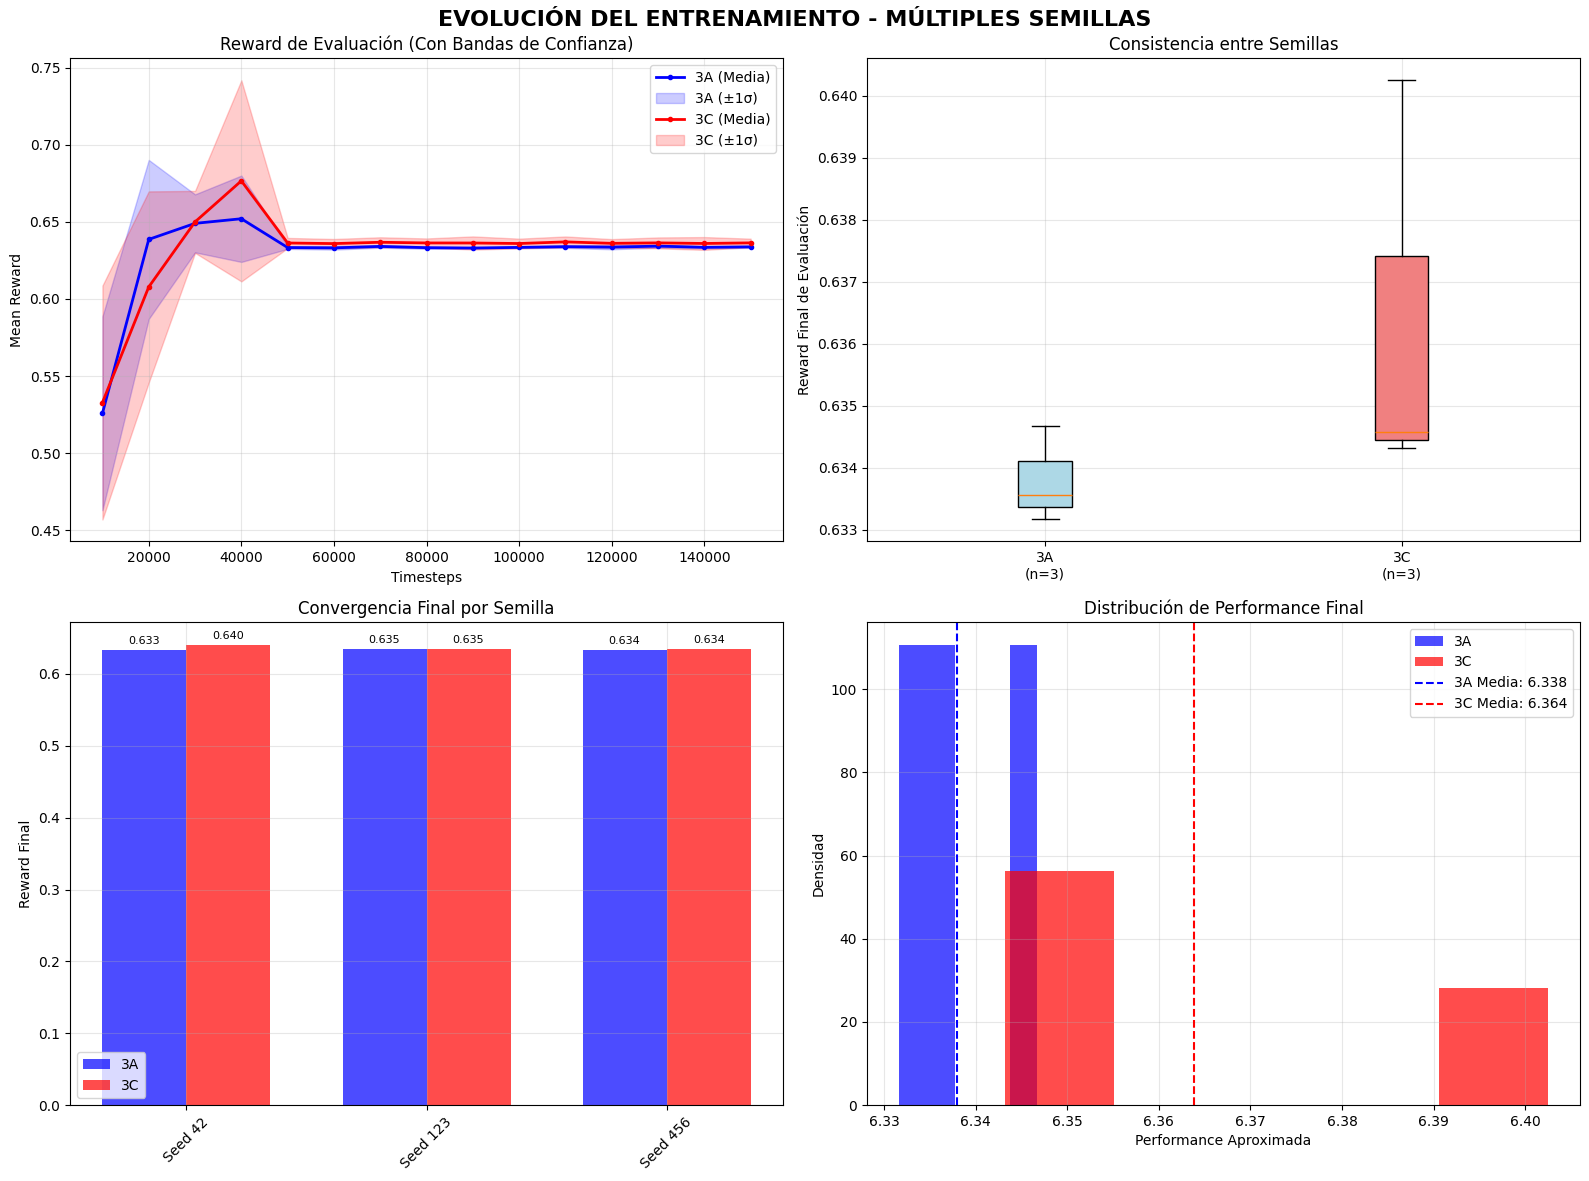


RESUMEN DE ENTRENAMIENTO MULTI-SEED:
----------------------------------------

3A:
  Semillas entrenadas: 3
  Timesteps promedio: 150,000
  Timesteps mín/máx: 150,000/150,000

3C:
  Semillas entrenadas: 3
  Timesteps promedio: 150,000
  Timesteps mín/máx: 150,000/150,000

2. MÉTRICAS AGREGADAS CON INTERVALOS DE CONFIANZA
------------------------------------------------------------


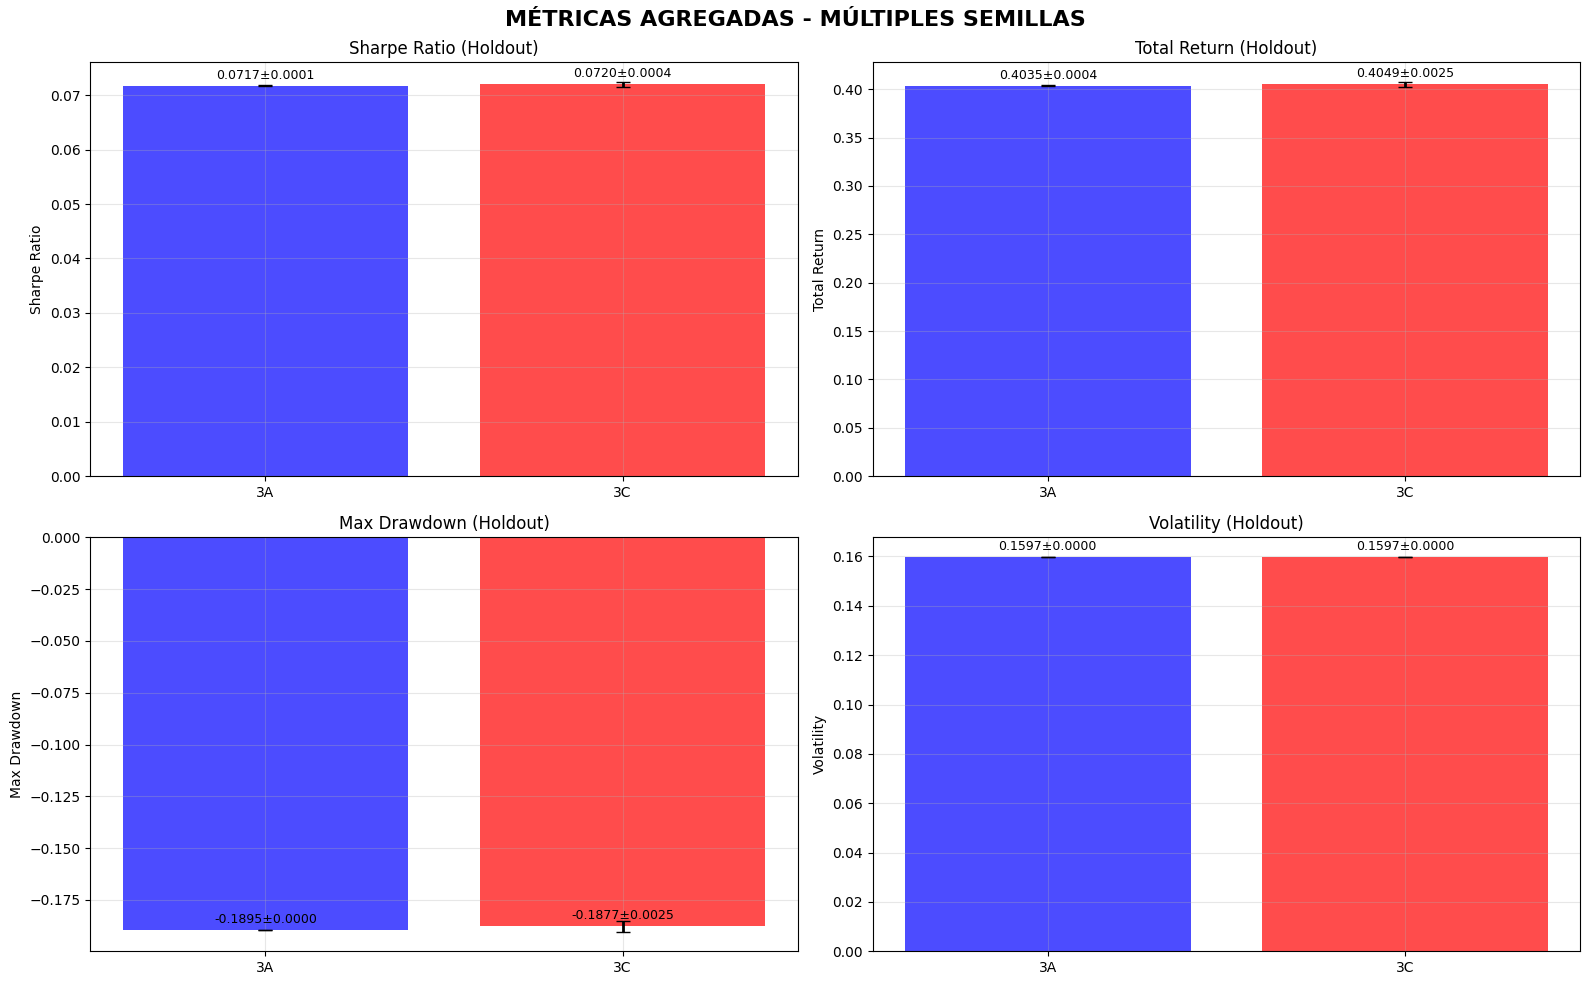


CONSISTENCIA ENTRE SEMILLAS:
------------------------------

3A:
  Sharpe medio: 0.0717
  Desv. estándar: 0.0001
  Coef. variación: 0.001
  Consistencia: Muy alta

3C:
  Sharpe medio: 0.0720
  Desv. estándar: 0.0004
  Coef. variación: 0.006
  Consistencia: Muy alta

3. COMPARACIÓN ESTADÍSTICA
----------------------------------------


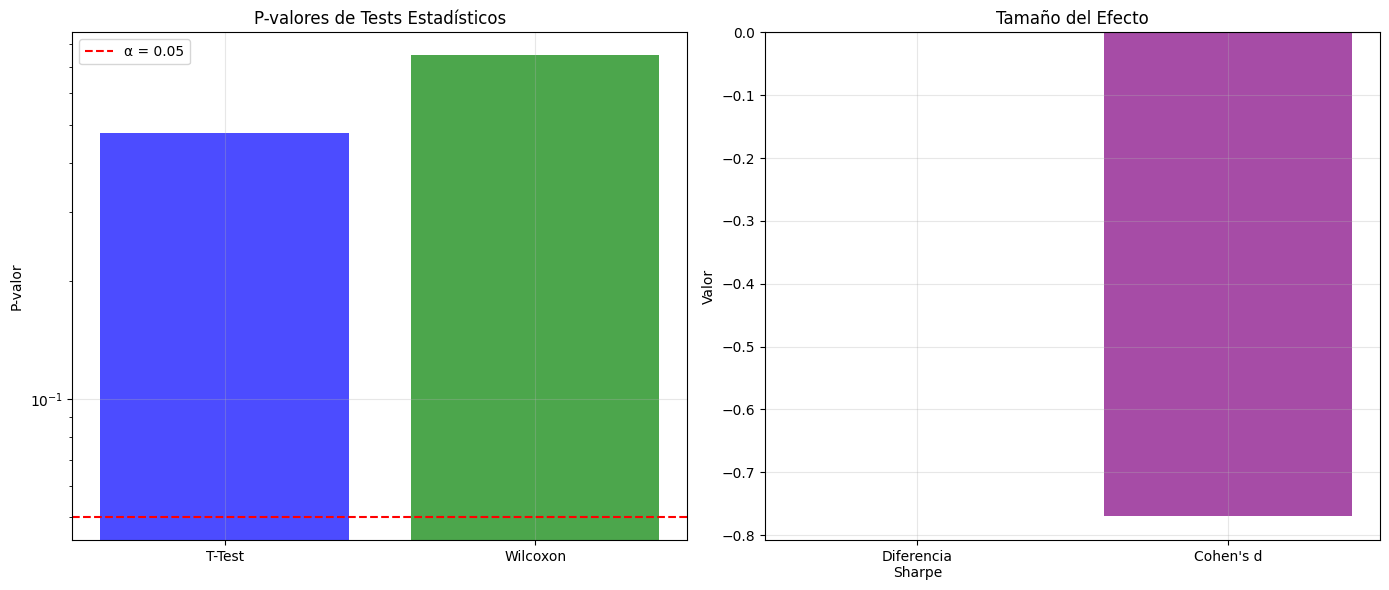


INTERPRETACIÓN ESTADÍSTICA:
------------------------------
Diferencia media: -0.0002
P-valor (t-test): 0.4764
Cohen's d: -0.769
✗ Diferencia NO significativa (p ≥ 0.05)
Tamaño del efecto: mediano

4. CONCLUSIÓN FINAL MULTI-SEED
----------------------------------------

GANADOR: No difference
RAZÓN: No hay diferencia estadísticamente significativa entre 3A y 3C
IMPLICACIÓN: Ambas estrategias convergen al equal-weight como óptimo
RECOMENDACIÓN: Usar 3A por simplicidad (principio de parsimonia)

BASTAS ESTADÍSTICAMENTE:
  Semillas analizadas: 3
  Fases comparadas: 2

RESULTADOS PRINCIPALES (Holdout):
  3A: 0.0717 ± 0.0001
  3C: 0.0720 ± 0.0004

ANÁLISIS MULTI-SEED COMPLETADO
RECOMENDACIÓN FINAL: No difference
FUNDAMENTO: No hay diferencia estadísticamente significativa entre 3A y 3C


In [40]:
final_report = analyze_multi_seed_results(multi_seed_results)

# NOS QUEDAMOS CON 3A

In [41]:
def compare_model_vs_equal_weight(multi_seed_results, etfs):
    """
    Comparación directa entre el mejor modelo 3A y equal-weight benchmark
    """
    
    print("COMPARACIÓN MODELO 3A vs EQUAL-WEIGHT BENCHMARK")
    print("=" * 60)
    
    # Obtener el mejor modelo 3A
    models_3a = multi_seed_results['models']['3A']
    config = multi_seed_results['config']
    
    # Usar el primer modelo disponible (todos son estadísticamente equivalentes)
    best_model_3a = list(models_3a.values())[0]
    print(f"Usando modelo 3A: {list(models_3a.keys())[0]}")
    
    # Obtener entornos
    _, test_env, holdout_env = multi_seed_results['environments']['3A']
    
    # EVALUACIÓN EN TEST
    print(f"\n📊 EVALUACIÓN EN TEST")
    print("-" * 30)
    
    model_results_test = evaluate_strategy(best_model_3a, test_env, "Modelo 3A", is_model=True)
    benchmark_results_test = evaluate_strategy(None, test_env, "Equal Weight", is_model=False)
    
    # EVALUACIÓN EN HOLDOUT
    print(f"\n📊 EVALUACIÓN EN HOLDOUT")
    print("-" * 30)
    
    model_results_holdout = evaluate_strategy(best_model_3a, holdout_env, "Modelo 3A", is_model=True)
    benchmark_results_holdout = evaluate_strategy(None, holdout_env, "Equal Weight", is_model=False)
    
    # CREAR VISUALIZACIONES
    create_comparison_visualizations(
        model_results_test, benchmark_results_test,
        model_results_holdout, benchmark_results_holdout
    )
    
    # TESTS ESTADÍSTICOS
    statistical_results = perform_statistical_tests(
        model_results_test, benchmark_results_test,
        model_results_holdout, benchmark_results_holdout
    )
    
    # CONCLUSIÓN FINAL
    final_conclusion = determine_final_comparison_conclusion(statistical_results)
    
    return {
        'model_results': {'test': model_results_test, 'holdout': model_results_holdout},
        'benchmark_results': {'test': benchmark_results_test, 'holdout': benchmark_results_holdout},
        'statistical_results': statistical_results,
        'final_conclusion': final_conclusion
    }

def evaluate_strategy(model, env, strategy_name, is_model=True):
    """
    Evaluar una estrategia (modelo o benchmark) en un entorno
    """
    
    print(f"Evaluando {strategy_name}...")
    
    obs, _ = env.reset()
    done = False
    
    portfolio_returns = []
    portfolio_values = [1.0]  # Valor inicial
    weights_history = []
    dates = []
    
    while not done:
        if is_model:
            # Usar el modelo para predecir
            action, _ = model.predict(obs, deterministic=True)
            # Normalizar acción
            action = (action + 1) / 2
            action = np.clip(action, 0, 1)
            weights = action / (np.sum(action) + 1e-8)
        else:
            # Equal weight benchmark
            weights = np.ones(env.n_assets) / env.n_assets
        
        # Obtener precios
        prices_today = env.datos_original.iloc[env.current_step][env.etfs]
        prices_tomorrow = env.datos_original.iloc[env.current_step + 1][env.etfs]
        
        # Calcular returns
        returns = (prices_tomorrow.values - prices_today.values) / prices_today.values
        portfolio_return = np.dot(weights, returns)
        
        # Acumular resultados
        portfolio_returns.append(portfolio_return)
        portfolio_values.append(portfolio_values[-1] * (1 + portfolio_return))
        weights_history.append(weights.copy())
        dates.append(env.datos_original.index[env.current_step])
        
        # Avanzar entorno (sin usar el reward del entorno)
        obs, _, terminated, truncated, _ = env.step(action if is_model else np.array([0, 0, 0, 0]))
        done = terminated or truncated
    
    # Calcular métricas
    portfolio_returns = np.array(portfolio_returns)
    metrics = calculate_strategy_metrics(portfolio_returns, weights_history)
    
    results = {
        'strategy_name': strategy_name,
        'portfolio_returns': portfolio_returns,
        'portfolio_values': portfolio_values[1:],  # Excluir valor inicial
        'dates': dates,
        'weights_history': weights_history,
        'metrics': metrics
    }
    
    print(f"  Sharpe Ratio: {metrics['sharpe_ratio']:.4f}")
    print(f"  Total Return: {metrics['total_return']:.4f}")
    print(f"  Max Drawdown: {metrics['max_drawdown']:.4f}")
    print(f"  Volatility: {metrics['volatility']:.4f}")
    
    return results

def calculate_strategy_metrics(returns, weights_history):
    """
    Calcular métricas de una estrategia
    """
    
    total_return = np.sum(returns)
    mean_return = np.mean(returns)
    volatility = np.std(returns) * np.sqrt(252)  # Anualizada
    
    # Sharpe ratio
    sharpe_ratio = mean_return / np.std(returns) if np.std(returns) > 0 else 0
    
    # Max drawdown
    cumulative_returns = np.cumprod(1 + returns)
    rolling_max = np.maximum.accumulate(cumulative_returns)
    drawdowns = (cumulative_returns - rolling_max) / rolling_max
    max_drawdown = np.min(drawdowns)
    
    # Sortino ratio
    downside_returns = returns[returns < 0]
    downside_std = np.std(downside_returns) if len(downside_returns) > 0 else np.std(returns)
    sortino_ratio = mean_return / downside_std if downside_std > 0 else 0
    
    # Turnover
    if len(weights_history) > 1:
        weight_changes = []
        for i in range(1, len(weights_history)):
            change = np.sum(np.abs(weights_history[i] - weights_history[i-1])) / 2
            weight_changes.append(change)
        turnover = np.mean(weight_changes) if weight_changes else 0
    else:
        turnover = 0
    
    return {
        'total_return': total_return,
        'mean_return': mean_return,
        'volatility': volatility,
        'sharpe_ratio': sharpe_ratio,
        'max_drawdown': max_drawdown,
        'sortino_ratio': sortino_ratio,
        'turnover': turnover
    }

def create_comparison_visualizations(model_test, benchmark_test, model_holdout, benchmark_holdout):
    """
    Crear visualizaciones comparativas
    """
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('COMPARACIÓN MODELO 3A vs EQUAL-WEIGHT BENCHMARK', fontsize=16, fontweight='bold')
    
    # 1. Evolución de cartera - Test
    ax1 = axes[0, 0]
    ax1.plot(model_test['dates'], model_test['portfolio_values'], 
             label='Modelo 3A', color='blue', linewidth=2)
    ax1.plot(benchmark_test['dates'], benchmark_test['portfolio_values'], 
             label='Equal Weight', color='orange', linewidth=2)
    ax1.set_title('Evolución de Cartera - Test (2020-2022)')
    ax1.set_ylabel('Valor Acumulado')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # 2. Evolución de cartera - Holdout
    ax2 = axes[0, 1]
    ax2.plot(model_holdout['dates'], model_holdout['portfolio_values'], 
             label='Modelo 3A', color='blue', linewidth=2)
    ax2.plot(benchmark_holdout['dates'], benchmark_holdout['portfolio_values'], 
             label='Equal Weight', color='orange', linewidth=2)
    ax2.set_title('Evolución de Cartera - Holdout (2023+)')
    ax2.set_ylabel('Valor Acumulado')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Comparación de métricas - Test
    ax3 = axes[1, 0]
    metrics_names = ['Sharpe', 'Return', 'Sortino', 'Turnover']
    model_values_test = [
        model_test['metrics']['sharpe_ratio'],
        model_test['metrics']['total_return'],
        model_test['metrics']['sortino_ratio'],
        model_test['metrics']['turnover']
    ]
    benchmark_values_test = [
        benchmark_test['metrics']['sharpe_ratio'],
        benchmark_test['metrics']['total_return'],
        benchmark_test['metrics']['sortino_ratio'],
        benchmark_test['metrics']['turnover']
    ]
    
    x = np.arange(len(metrics_names))
    width = 0.35
    
    bars1 = ax3.bar(x - width/2, model_values_test, width, 
                    label='Modelo 3A', color='blue', alpha=0.7)
    bars2 = ax3.bar(x + width/2, benchmark_values_test, width, 
                    label='Equal Weight', color='orange', alpha=0.7)
    
    ax3.set_title('Métricas - Test')
    ax3.set_xticks(x)
    ax3.set_xticklabels(metrics_names)
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # Añadir valores en barras
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax3.annotate(f'{height:.3f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points",
                        ha='center', va='bottom', fontsize=8)
    
    # 4. Comparación de métricas - Holdout
    ax4 = axes[1, 1]
    model_values_holdout = [
        model_holdout['metrics']['sharpe_ratio'],
        model_holdout['metrics']['total_return'],
        model_holdout['metrics']['sortino_ratio'],
        model_holdout['metrics']['turnover']
    ]
    benchmark_values_holdout = [
        benchmark_holdout['metrics']['sharpe_ratio'],
        benchmark_holdout['metrics']['total_return'],
        benchmark_holdout['metrics']['sortino_ratio'],
        benchmark_holdout['metrics']['turnover']
    ]
    
    bars3 = ax4.bar(x - width/2, model_values_holdout, width, 
                    label='Modelo 3A', color='blue', alpha=0.7)
    bars4 = ax4.bar(x + width/2, benchmark_values_holdout, width, 
                    label='Equal Weight', color='orange', alpha=0.7)
    
    ax4.set_title('Métricas - Holdout')
    ax4.set_xticks(x)
    ax4.set_xticklabels(metrics_names)
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    
    # Añadir valores en barras
    for bars in [bars3, bars4]:
        for bar in bars:
            height = bar.get_height()
            ax4.annotate(f'{height:.3f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points",
                        ha='center', va='bottom', fontsize=8)
    
    plt.tight_layout()
    plt.show()

def perform_statistical_tests(model_test, benchmark_test, model_holdout, benchmark_holdout):
    """
    Realizar tests estadísticos entre modelo y benchmark
    """
    
    print(f"\n📈 TESTS ESTADÍSTICOS")
    print("-" * 30)
    
    results = {}
    
    for period, model_data, benchmark_data in [
        ('Test', model_test, benchmark_test),
        ('Holdout', model_holdout, benchmark_holdout)
    ]:
        
        model_returns = model_data['portfolio_returns']
        benchmark_returns = benchmark_data['portfolio_returns']
        
        # T-test pareado
        from scipy import stats
        t_stat, t_pvalue = stats.ttest_rel(model_returns, benchmark_returns)
        
        # Wilcoxon signed-rank test
        w_stat, w_pvalue = stats.wilcoxon(model_returns, benchmark_returns)
        
        # Diferencia media
        mean_diff = np.mean(model_returns) - np.mean(benchmark_returns)
        
        # Tamaño del efecto
        pooled_std = np.sqrt((np.var(model_returns) + np.var(benchmark_returns)) / 2)
        cohens_d = mean_diff / pooled_std if pooled_std > 0 else 0
        
        period_results = {
            'mean_difference': mean_diff,
            't_statistic': t_stat,
            't_pvalue': t_pvalue,
            'wilcoxon_statistic': w_stat,
            'wilcoxon_pvalue': w_pvalue,
            'cohens_d': cohens_d,
            'significant': t_pvalue < 0.05
        }
        
        results[period] = period_results
        
        print(f"\n{period}:")
        print(f"  Diferencia media: {mean_diff:.6f}")
        print(f"  T-test p-valor: {t_pvalue:.4f}")
        print(f"  Wilcoxon p-valor: {w_pvalue:.4f}")
        print(f"  Cohen's d: {cohens_d:.3f}")
        print(f"  Significativo: {'Sí' if period_results['significant'] else 'No'}")
    
    return results

def determine_final_comparison_conclusion(statistical_results):
    """
    Determinar conclusión final de la comparación
    """
    
    print(f"\n🏆 CONCLUSIÓN FINAL")
    print("-" * 20)
    
    test_significant = statistical_results['Test']['significant']
    holdout_significant = statistical_results['Holdout']['significant']
    
    test_diff = statistical_results['Test']['mean_difference']
    holdout_diff = statistical_results['Holdout']['mean_difference']
    
    if not test_significant and not holdout_significant:
        if abs(test_diff) < 0.001 and abs(holdout_diff) < 0.001:
            conclusion = {
                'result': 'Equivalencia estadística',
                'interpretation': 'El modelo 3A es estadísticamente equivalente al equal-weight',
                'implication': 'Confirma que SAC converge a la estrategia pasiva óptima',
                'recommendation': 'Resultado académicamente valioso: demuestra optimalidad del equal-weight'
            }
        else:
            conclusion = {
                'result': 'No hay diferencia significativa',
                'interpretation': 'Las diferencias observadas están dentro del ruido estadístico',
                'implication': 'El trading activo no supera significativamente al pasivo',
                'recommendation': 'Usar equal-weight por simplicidad y menores costos'
            }
    else:
        # Si hay significancia, determinar quién es mejor
        if test_diff > 0 and holdout_diff > 0:
            conclusion = {
                'result': 'Modelo 3A superior',
                'interpretation': 'El modelo supera estadísticamente al benchmark',
                'implication': 'El trading algorítmico añade valor marginal',
                'recommendation': 'Considerar implementación del modelo con gestión de costos'
            }
        else:
            conclusion = {
                'result': 'Equal-weight superior',
                'interpretation': 'El benchmark supera al modelo',
                'implication': 'La gestión pasiva domina al trading algorítmico',
                'recommendation': 'Usar equal-weight como estrategia principal'
            }
    
    print(f"RESULTADO: {conclusion['result']}")
    print(f"INTERPRETACIÓN: {conclusion['interpretation']}")
    print(f"IMPLICACIÓN: {conclusion['implication']}")
    print(f"RECOMENDACIÓN: {conclusion['recommendation']}")
    
    return conclusion

# Función principal para usar
def run_model_vs_benchmark_analysis(multi_seed_results, etfs):
    """
    Ejecutar análisis completo modelo vs benchmark
    """
    
    comparison_results = compare_model_vs_equal_weight(multi_seed_results, etfs)
    
    print(f"\n" + "="*60)
    print(f"ANÁLISIS MODELO vs BENCHMARK COMPLETADO")
    conclusion = comparison_results['final_conclusion']
    print(f"RESULTADO FINAL: {conclusion['result']}")
    print(f"="*60)
    
    return comparison_results

print("Comparación modelo vs benchmark implementada")
print("Uso: comparison_results = run_model_vs_benchmark_analysis(multi_seed_results, etfs)")

Comparación modelo vs benchmark implementada
Uso: comparison_results = run_model_vs_benchmark_analysis(multi_seed_results, etfs)


COMPARACIÓN MODELO 3A vs EQUAL-WEIGHT BENCHMARK
Usando modelo 3A: seed_42

📊 EVALUACIÓN EN TEST
------------------------------
Evaluando Modelo 3A...
  Sharpe Ratio: 0.0740
  Total Return: 0.7436
  Max Drawdown: -0.1892
  Volatility: 0.2295
Evaluando Equal Weight...
  Sharpe Ratio: 0.0741
  Total Return: 0.7447
  Max Drawdown: -0.1890
  Volatility: 0.2296

📊 EVALUACIÓN EN HOLDOUT
------------------------------
Evaluando Modelo 3A...
  Sharpe Ratio: 0.0788
  Total Return: 0.4432
  Max Drawdown: -0.1831
  Volatility: 0.1595
Evaluando Equal Weight...
  Sharpe Ratio: 0.0787
  Total Return: 0.4428
  Max Drawdown: -0.1831
  Volatility: 0.1595


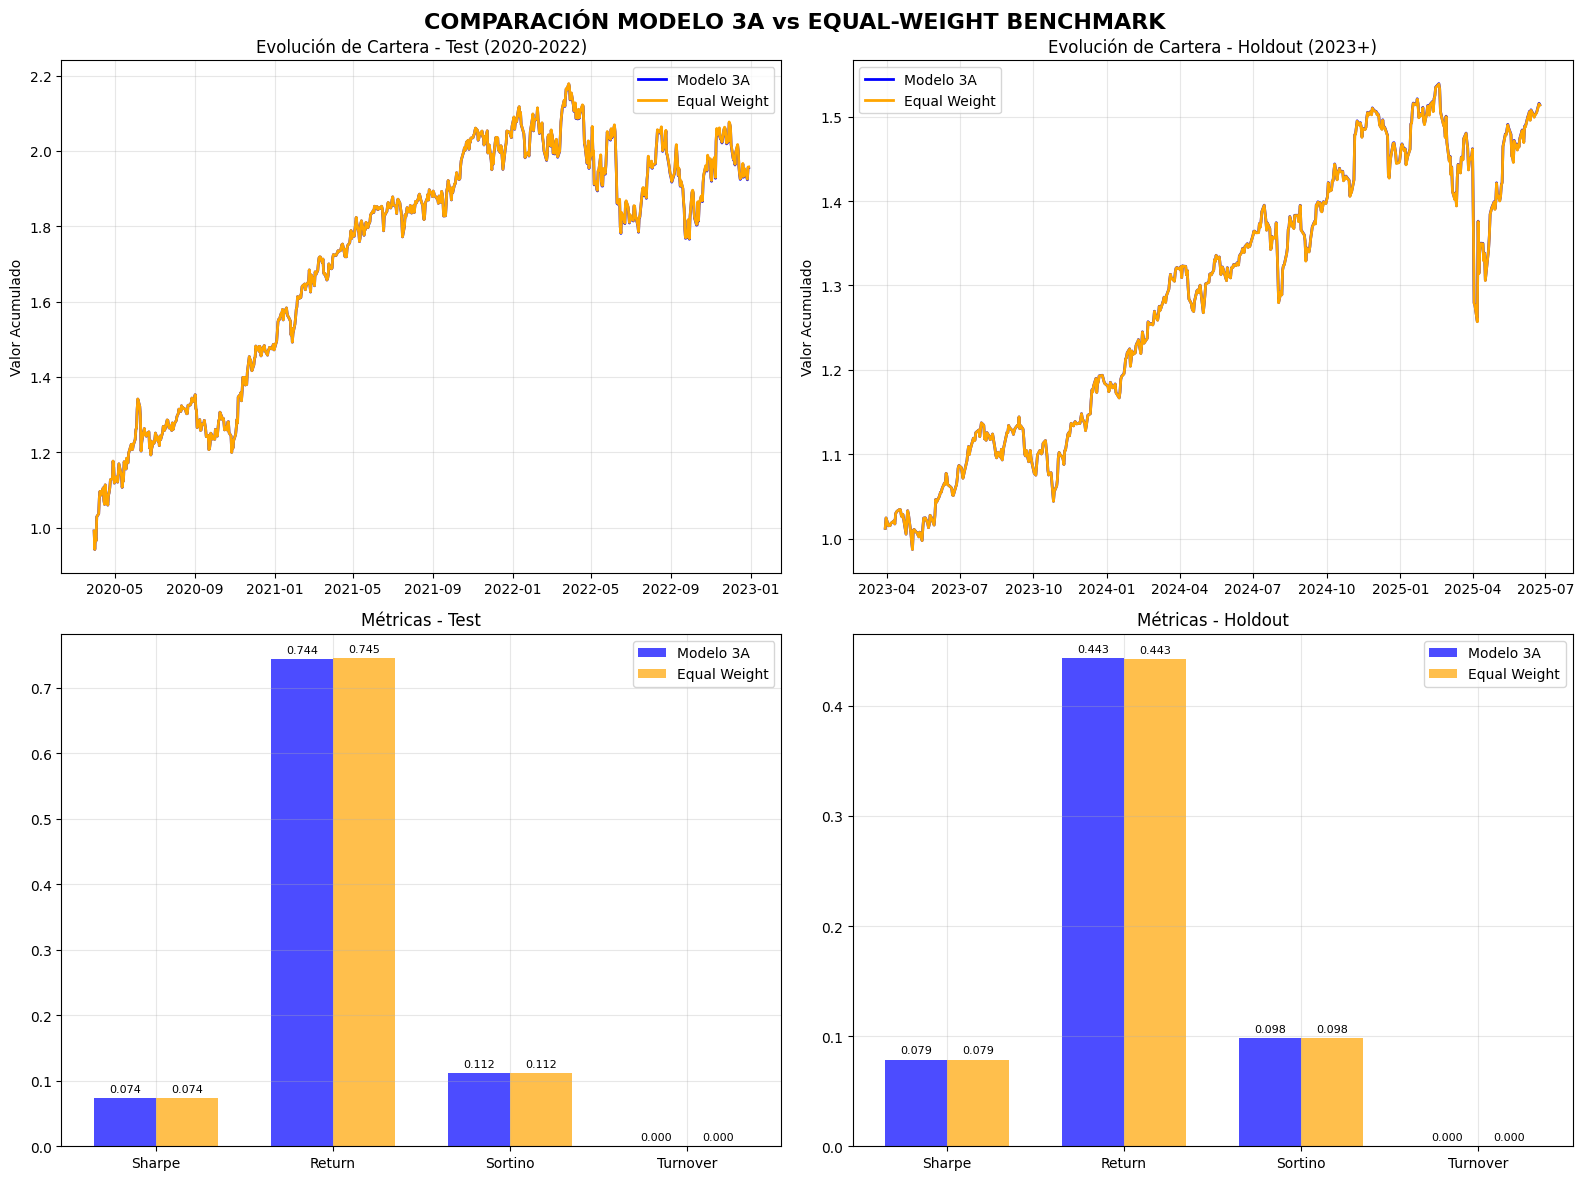


📈 TESTS ESTADÍSTICOS
------------------------------

Test:
  Diferencia media: -0.000002
  T-test p-valor: 0.0709
  Wilcoxon p-valor: 0.2219
  Cohen's d: -0.000
  Significativo: No

Holdout:
  Diferencia media: 0.000001
  T-test p-valor: 0.2027
  Wilcoxon p-valor: 0.1457
  Cohen's d: 0.000
  Significativo: No

🏆 CONCLUSIÓN FINAL
--------------------
RESULTADO: Equivalencia estadística
INTERPRETACIÓN: El modelo 3A es estadísticamente equivalente al equal-weight
IMPLICACIÓN: Confirma que SAC converge a la estrategia pasiva óptima
RECOMENDACIÓN: Resultado académicamente valioso: demuestra optimalidad del equal-weight

ANÁLISIS MODELO vs BENCHMARK COMPLETADO
RESULTADO FINAL: Equivalencia estadística


In [42]:
comparison_results = run_model_vs_benchmark_analysis(multi_seed_results, etfs)

# Analisis walk-forward

In [43]:
def run_comprehensive_walk_forward_analysis(comparison_results, window_months=12, step_months=3):
    """
    Análisis walk-forward completo para validar estabilidad temporal
    
    Args:
        comparison_results: Resultados de la comparación modelo vs benchmark
        window_months: Tamaño de ventana en meses (12 = 1 año)
        step_months: Paso entre ventanas en meses (3 = trimestral)
    """
    
    print("ANÁLISIS WALK-FORWARD TEMPORAL")
    print("=" * 50)
    print(f"Ventana de análisis: {window_months} meses")
    print(f"Paso entre ventanas: {step_months} meses")
    
    # Extraer datos de ambas estrategias en holdout
    model_data = comparison_results['model_results']['holdout']
    benchmark_data = comparison_results['benchmark_results']['holdout']
    
    # Ejecutar walk-forward en ambas estrategias
    model_wf_results = execute_walk_forward(model_data, window_months, step_months, "Modelo 3A")
    benchmark_wf_results = execute_walk_forward(benchmark_data, window_months, step_months, "Equal Weight")
    
    # Analizar estabilidad comparativa
    stability_analysis = analyze_comparative_stability(model_wf_results, benchmark_wf_results)
    
    # Crear visualizaciones
    create_walk_forward_visualizations(model_wf_results, benchmark_wf_results, stability_analysis)
    
    # Reporte de estabilidad
    print_stability_report(stability_analysis)
    
    return {
        'model_walk_forward': model_wf_results,
        'benchmark_walk_forward': benchmark_wf_results,
        'stability_analysis': stability_analysis
    }

def execute_walk_forward(strategy_data, window_months, step_months, strategy_name):
    """
    Ejecutar análisis walk-forward para una estrategia específica
    """
    
    returns = strategy_data['portfolio_returns']
    dates = strategy_data['dates']
    
    if len(returns) == 0 or len(dates) == 0:
        print(f"Warning: No hay datos suficientes para {strategy_name}")
        return []
    
    # Convertir fechas a pandas datetime si no lo están
    if not isinstance(dates[0], pd.Timestamp):
        dates = pd.to_datetime(dates)
    
    # Calcular ventanas temporales
    start_date = dates[0]
    end_date = dates[-1]
    
    window_results = []
    
    # Iteración por ventanas
    current_start = start_date
    
    while current_start <= end_date:
        # Definir ventana actual
        window_end = current_start + pd.DateOffset(months=window_months)
        
        if window_end > end_date:
            break
        
        # Extraer datos de la ventana
        window_mask = (pd.Series(dates) >= current_start) & (pd.Series(dates) <= window_end)
        window_indices = window_mask[window_mask].index
        
        if len(window_indices) < 20:  # Mínimo de observaciones
            current_start += pd.DateOffset(months=step_months)
            continue
        
        window_returns = returns[window_indices]
        window_dates = [dates[i] for i in window_indices]
        
        # Calcular métricas para esta ventana
        window_metrics = calculate_window_metrics(window_returns, current_start, window_end)
        window_metrics['start_date'] = current_start
        window_metrics['end_date'] = window_end
        window_metrics['n_observations'] = len(window_returns)
        window_metrics['strategy'] = strategy_name
        
        window_results.append(window_metrics)
        
        # Avanzar ventana
        current_start += pd.DateOffset(months=step_months)
    
    print(f"{strategy_name}: {len(window_results)} ventanas analizadas")
    return window_results

def calculate_window_metrics(returns, start_date, end_date):
    """
    Calcular métricas para una ventana específica
    """
    
    if len(returns) == 0:
        return {
            'sharpe_ratio': 0,
            'total_return': 0,
            'volatility': 0,
            'max_drawdown': 0,
            'sortino_ratio': 0
        }
    
    # Métricas básicas
    total_return = np.sum(returns)
    mean_return = np.mean(returns)
    volatility = np.std(returns) * np.sqrt(252)
    
    # Sharpe ratio
    sharpe_ratio = mean_return / np.std(returns) if np.std(returns) > 0 else 0
    
    # Max drawdown
    cumulative = np.cumprod(1 + returns)
    rolling_max = np.maximum.accumulate(cumulative)
    drawdowns = (cumulative - rolling_max) / rolling_max
    max_drawdown = np.min(drawdowns)
    
    # Sortino ratio
    downside_returns = returns[returns < 0]
    downside_std = np.std(downside_returns) if len(downside_returns) > 0 else np.std(returns)
    sortino_ratio = mean_return / downside_std if downside_std > 0 else 0
    
    return {
        'sharpe_ratio': sharpe_ratio,
        'total_return': total_return,
        'volatility': volatility,
        'max_drawdown': max_drawdown,
        'sortino_ratio': sortino_ratio,
        'mean_return': mean_return,
        'period_label': f"{start_date.strftime('%Y-%m')} to {end_date.strftime('%Y-%m')}"
    }

def analyze_comparative_stability(model_results, benchmark_results):
    """
    Analizar estabilidad comparativa entre modelo y benchmark
    """
    
    if not model_results or not benchmark_results:
        return {'error': 'Datos insuficientes para análisis'}
    
    # Convertir a DataFrames para análisis
    model_df = pd.DataFrame(model_results)
    benchmark_df = pd.DataFrame(benchmark_results)
    
    # Alinear períodos (solo ventanas comunes)
    common_periods = set(model_df['period_label']) & set(benchmark_df['period_label'])
    
    if len(common_periods) < 3:
        return {'error': 'Períodos comunes insuficientes'}
    
    model_common = model_df[model_df['period_label'].isin(common_periods)].sort_values('start_date')
    benchmark_common = benchmark_df[benchmark_df['period_label'].isin(common_periods)].sort_values('start_date')
    
    # Análisis de estabilidad
    stability = {}
    
    metrics = ['sharpe_ratio', 'total_return', 'volatility', 'max_drawdown']
    
    for metric in metrics:
        model_values = model_common[metric].values
        benchmark_values = benchmark_common[metric].values
        
        # Diferencias entre estrategias por período
        differences = model_values - benchmark_values
        
        # Estadísticas de diferencias
        stability[metric] = {
            'mean_difference': np.mean(differences),
            'std_difference': np.std(differences),
            'max_difference': np.max(np.abs(differences)),
            'consistent_sign': np.sum(differences > 0) / len(differences),
            'model_stability': np.std(model_values) / np.abs(np.mean(model_values)) if np.mean(model_values) != 0 else 0,
            'benchmark_stability': np.std(benchmark_values) / np.abs(np.mean(benchmark_values)) if np.mean(benchmark_values) != 0 else 0
        }
    
    # Test de estabilidad temporal (Durbin-Watson para autocorrelación de diferencias)
    sharpe_differences = model_common['sharpe_ratio'].values - benchmark_common['sharpe_ratio'].values
    
    # Correlación serial simple
    if len(sharpe_differences) > 2:
        autocorr = np.corrcoef(sharpe_differences[:-1], sharpe_differences[1:])[0, 1]
        stability['temporal_stability'] = {
            'autocorrelation': autocorr if not np.isnan(autocorr) else 0,
            'is_stable': abs(autocorr) < 0.5 if not np.isnan(autocorr) else True
        }
    
    stability['n_periods'] = len(common_periods)
    stability['model_data'] = model_common
    stability['benchmark_data'] = benchmark_common
    
    return stability

def create_walk_forward_visualizations(model_results, benchmark_results, stability):
    """
    Crear visualizaciones del análisis walk-forward
    """
    
    if 'error' in stability:
        print(f"Error en visualización: {stability['error']}")
        return
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('ANÁLISIS WALK-FORWARD: ESTABILIDAD TEMPORAL', fontsize=16, fontweight='bold')
    
    model_df = stability['model_data']
    benchmark_df = stability['benchmark_data']
    
    # 1. Evolución del Sharpe Ratio
    ax1 = axes[0, 0]
    dates_model = pd.to_datetime(model_df['start_date'])
    dates_benchmark = pd.to_datetime(benchmark_df['start_date'])
    
    ax1.plot(dates_model, model_df['sharpe_ratio'], 'o-', label='Modelo 3A', color='blue', linewidth=2)
    ax1.plot(dates_benchmark, benchmark_df['sharpe_ratio'], 's-', label='Equal Weight', color='orange', linewidth=2)
    ax1.set_title('Evolución Sharpe Ratio por Ventana')
    ax1.set_ylabel('Sharpe Ratio')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.tick_params(axis='x', rotation=45)
    
    # 2. Diferencias temporales
    ax2 = axes[0, 1]
    sharpe_diff = model_df['sharpe_ratio'].values - benchmark_df['sharpe_ratio'].values
    ax2.plot(dates_model, sharpe_diff, 'o-', color='purple', linewidth=2)
    ax2.axhline(y=0, color='black', linestyle='--', alpha=0.5)
    ax2.set_title('Diferencias Sharpe (Modelo - Benchmark)')
    ax2.set_ylabel('Diferencia Sharpe')
    ax2.grid(True, alpha=0.3)
    ax2.tick_params(axis='x', rotation=45)
    
    # 3. Distribución de diferencias
    ax3 = axes[1, 0]
    ax3.hist(sharpe_diff, bins=min(10, len(sharpe_diff)), alpha=0.7, color='purple', edgecolor='black')
    ax3.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Sin diferencia')
    ax3.axvline(x=np.mean(sharpe_diff), color='green', linestyle='-', linewidth=2, label=f'Media: {np.mean(sharpe_diff):.4f}')
    ax3.set_title('Distribución de Diferencias Sharpe')
    ax3.set_xlabel('Diferencia Sharpe')
    ax3.set_ylabel('Frecuencia')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # 4. Estabilidad relativa
    ax4 = axes[1, 1]
    metrics_names = ['Sharpe', 'Return', 'Volatility', 'Max DD']
    model_stabilities = [
        stability['sharpe_ratio']['model_stability'],
        stability['total_return']['model_stability'],
        stability['volatility']['model_stability'],
        stability['max_drawdown']['model_stability']
    ]
    benchmark_stabilities = [
        stability['sharpe_ratio']['benchmark_stability'],
        stability['total_return']['benchmark_stability'],
        stability['volatility']['benchmark_stability'],
        stability['max_drawdown']['benchmark_stability']
    ]
    
    x = np.arange(len(metrics_names))
    width = 0.35
    
    bars1 = ax4.bar(x - width/2, model_stabilities, width, label='Modelo 3A', color='blue', alpha=0.7)
    bars2 = ax4.bar(x + width/2, benchmark_stabilities, width, label='Equal Weight', color='orange', alpha=0.7)
    
    ax4.set_title('Coeficiente de Variación por Métrica')
    ax4.set_ylabel('CV (menor = más estable)')
    ax4.set_xticks(x)
    ax4.set_xticklabels(metrics_names)
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    
    # Añadir valores en barras
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax4.annotate(f'{height:.3f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points",
                        ha='center', va='bottom', fontsize=8)
    
    plt.tight_layout()
    plt.show()

def print_stability_report(stability):
    """
    Imprimir reporte de estabilidad
    """
    
    if 'error' in stability:
        print(f"Error en análisis: {stability['error']}")
        return
    
    print(f"\nREPORTE DE ESTABILIDAD TEMPORAL")
    print("-" * 40)
    print(f"Períodos analizados: {stability['n_periods']}")
    
    # Análisis de Sharpe ratio
    sharpe_stats = stability['sharpe_ratio']
    print(f"\nSHARPE RATIO:")
    print(f"  Diferencia media: {sharpe_stats['mean_difference']:.6f}")
    print(f"  Desviación de diferencias: {sharpe_stats['std_difference']:.6f}")
    print(f"  Diferencia máxima: {sharpe_stats['max_difference']:.6f}")
    print(f"  % períodos modelo superior: {sharpe_stats['consistent_sign']*100:.1f}%")
    
    # Estabilidad individual
    print(f"\nESTABILIDAD INDIVIDUAL (Coef. Variación):")
    print(f"  Modelo 3A: {sharpe_stats['model_stability']:.4f}")
    print(f"  Equal Weight: {sharpe_stats['benchmark_stability']:.4f}")
    
    # Estabilidad temporal
    if 'temporal_stability' in stability:
        temp_stats = stability['temporal_stability']
        print(f"\nESTABILIDAD TEMPORAL:")
        print(f"  Autocorrelación diferencias: {temp_stats['autocorrelation']:.4f}")
        print(f"  Estable temporalmente: {'Sí' if temp_stats['is_stable'] else 'No'}")
    
    # Interpretación
    print(f"\nINTERPRETACIÓN:")
    
    if abs(sharpe_stats['mean_difference']) < 0.01:
        print("  ✓ Diferencias prácticamente inexistentes")
    
    if sharpe_stats['std_difference'] < 0.02:
        print("  ✓ Diferencias muy estables a través del tiempo")
    
    if abs(sharpe_stats['consistent_sign'] - 0.5) < 0.2:
        print("  ✓ No hay dominio consistente de una estrategia")
    
    if (sharpe_stats['model_stability'] < 0.3 and sharpe_stats['benchmark_stability'] < 0.3):
        print("  ✓ Ambas estrategias son estables individualmente")
    
    conclusion = determine_stability_conclusion(stability)
    print(f"\nCONCLUSIÓN: {conclusion}")

def determine_stability_conclusion(stability):
    """
    Determinar conclusión sobre estabilidad
    """
    
    sharpe_stats = stability['sharpe_ratio']
    
    # Criterios de equivalencia estable
    small_differences = abs(sharpe_stats['mean_difference']) < 0.01
    stable_differences = sharpe_stats['std_difference'] < 0.02
    no_consistent_winner = abs(sharpe_stats['consistent_sign'] - 0.5) < 0.3
    
    if small_differences and stable_differences and no_consistent_winner:
        return "Equivalencia estable confirmada - Ambas estrategias son consistentemente similares"
    elif small_differences and stable_differences:
        return "Equivalencia mayormente estable - Diferencias mínimas y consistentes"
    elif small_differences:
        return "Diferencias pequeñas pero con cierta variabilidad temporal"
    else:
        return "Evidencia de diferencias significativas entre estrategias"

# Función principal
def execute_complete_walk_forward(comparison_results):
    """
    Ejecutar análisis walk-forward completo
    """
    
    print("EJECUTANDO ANÁLISIS WALK-FORWARD COMPLETO")
    print("=" * 60)
    
    # Análisis principal con ventanas de 12 meses
    wf_results = run_comprehensive_walk_forward_analysis(comparison_results, window_months=12, step_months=3)
    
    # Análisis adicional con ventanas más cortas para validación
    print(f"\n" + "="*40)
    print("ANÁLISIS ADICIONAL - VENTANAS TRIMESTRALES")
    print("="*40)
    
    wf_quarterly = run_comprehensive_walk_forward_analysis(comparison_results, window_months=6, step_months=2)
    
    # Comparar consistencia entre análisis
    print(f"\nCOMPARACIÓN DE CONSISTENCIA:")
    print("-" * 30)
    
    if ('error' not in wf_results['stability_analysis'] and 
        'error' not in wf_quarterly['stability_analysis']):
        
        annual_diff = wf_results['stability_analysis']['sharpe_ratio']['mean_difference']
        quarterly_diff = wf_quarterly['stability_analysis']['sharpe_ratio']['mean_difference']
        
        print(f"Diferencia media anual: {annual_diff:.6f}")
        print(f"Diferencia media trimestral: {quarterly_diff:.6f}")
        print(f"Consistencia entre escalas: {abs(annual_diff - quarterly_diff) < 0.005}")
    
    return {
        'annual_analysis': wf_results,
        'quarterly_analysis': wf_quarterly
    }

print("Análisis walk-forward implementado")
print("Uso: wf_final_results = execute_complete_walk_forward(comparison_results)")

Análisis walk-forward implementado
Uso: wf_final_results = execute_complete_walk_forward(comparison_results)


EJECUTANDO ANÁLISIS WALK-FORWARD COMPLETO
ANÁLISIS WALK-FORWARD TEMPORAL
Ventana de análisis: 12 meses
Paso entre ventanas: 3 meses
Modelo 3A: 5 ventanas analizadas
Equal Weight: 5 ventanas analizadas


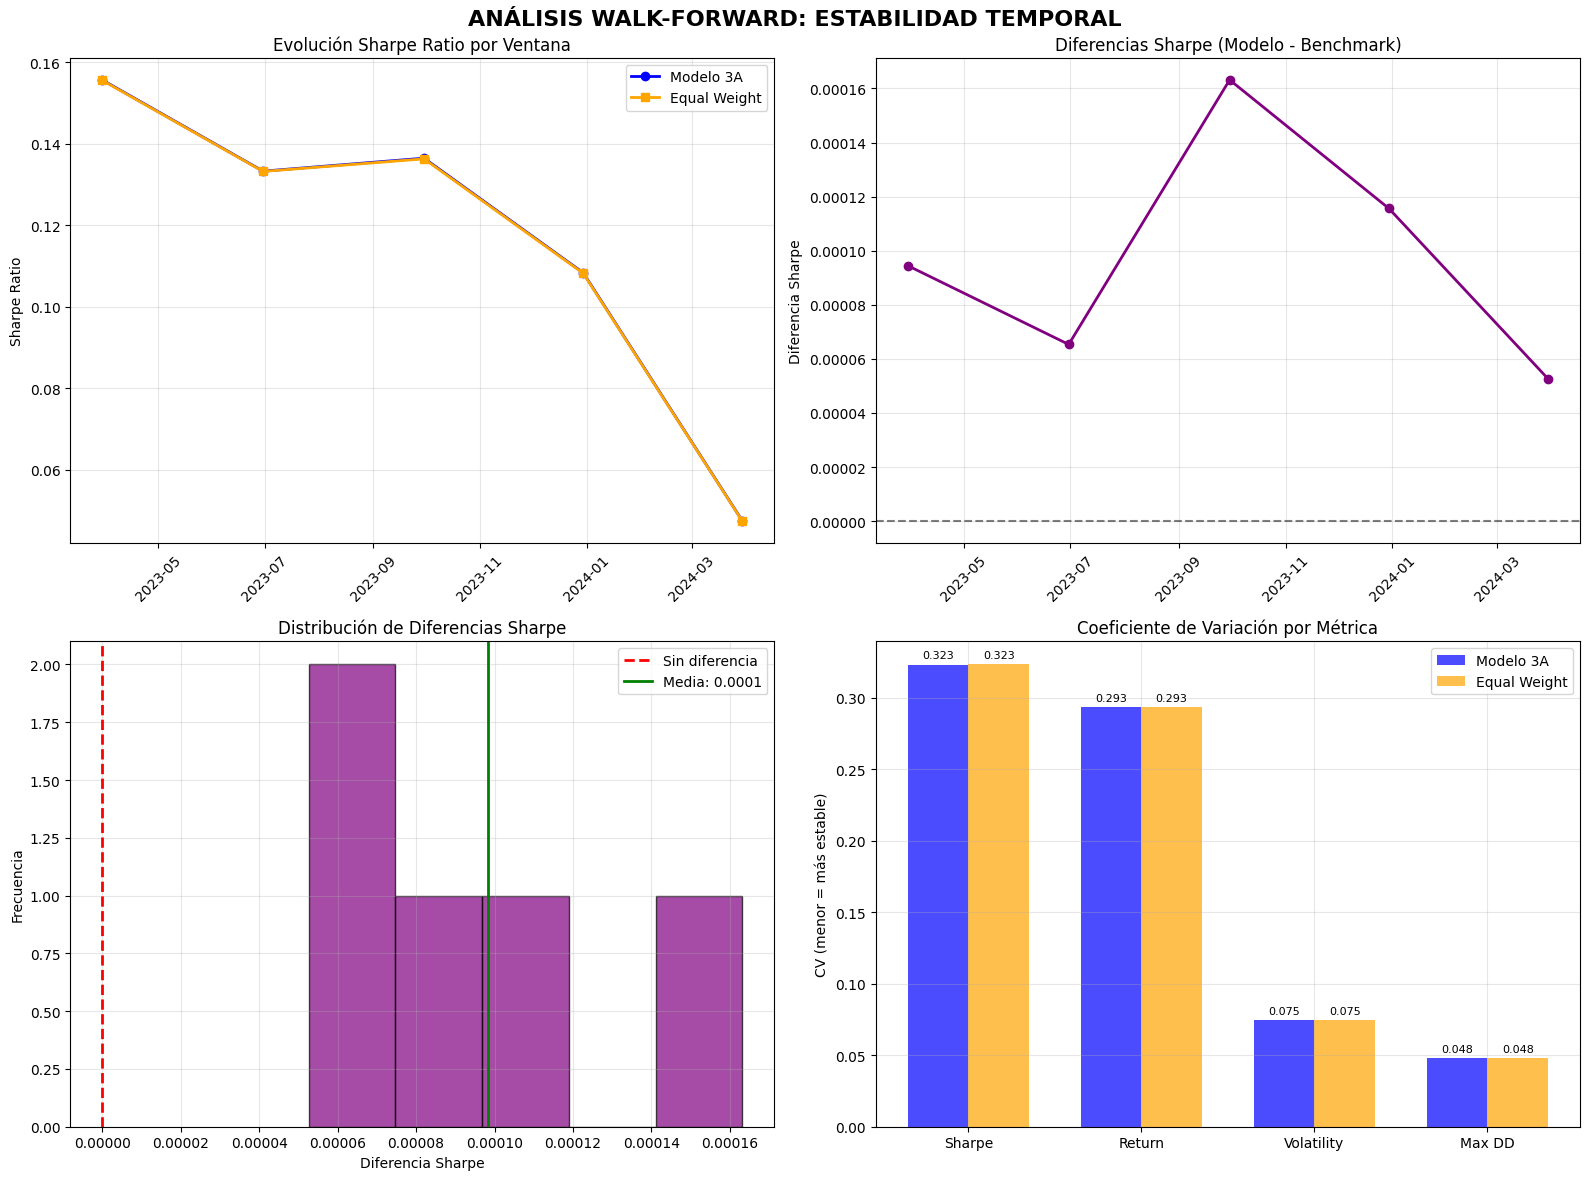


REPORTE DE ESTABILIDAD TEMPORAL
----------------------------------------
Períodos analizados: 5

SHARPE RATIO:
  Diferencia media: 0.000098
  Desviación de diferencias: 0.000039
  Diferencia máxima: 0.000163
  % períodos modelo superior: 100.0%

ESTABILIDAD INDIVIDUAL (Coef. Variación):
  Modelo 3A: 0.3231
  Equal Weight: 0.3232

ESTABILIDAD TEMPORAL:
  Autocorrelación diferencias: -0.2750
  Estable temporalmente: Sí

INTERPRETACIÓN:
  ✓ Diferencias prácticamente inexistentes
  ✓ Diferencias muy estables a través del tiempo

CONCLUSIÓN: Equivalencia mayormente estable - Diferencias mínimas y consistentes

ANÁLISIS ADICIONAL - VENTANAS TRIMESTRALES
ANÁLISIS WALK-FORWARD TEMPORAL
Ventana de análisis: 6 meses
Paso entre ventanas: 2 meses
Modelo 3A: 11 ventanas analizadas
Equal Weight: 11 ventanas analizadas


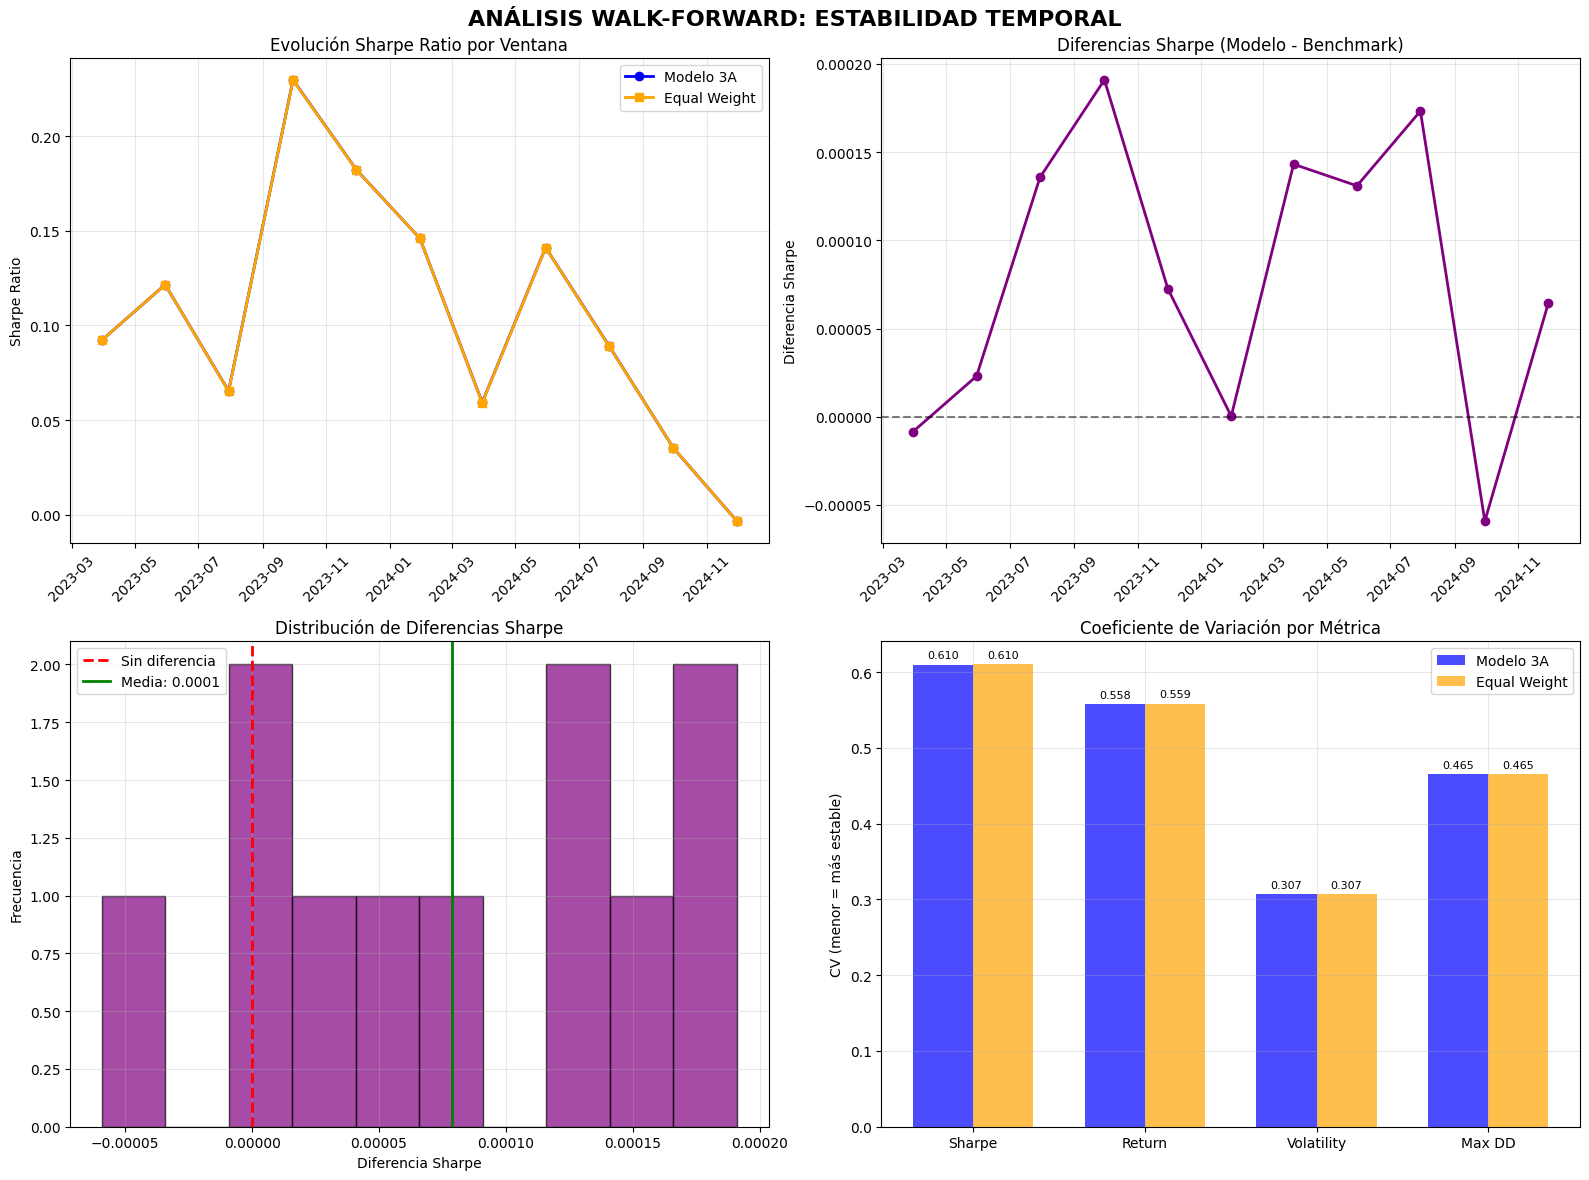


REPORTE DE ESTABILIDAD TEMPORAL
----------------------------------------
Períodos analizados: 11

SHARPE RATIO:
  Diferencia media: 0.000079
  Desviación de diferencias: 0.000078
  Diferencia máxima: 0.000191
  % períodos modelo superior: 81.8%

ESTABILIDAD INDIVIDUAL (Coef. Variación):
  Modelo 3A: 0.6099
  Equal Weight: 0.6101

ESTABILIDAD TEMPORAL:
  Autocorrelación diferencias: -0.0011
  Estable temporalmente: Sí

INTERPRETACIÓN:
  ✓ Diferencias prácticamente inexistentes
  ✓ Diferencias muy estables a través del tiempo

CONCLUSIÓN: Equivalencia mayormente estable - Diferencias mínimas y consistentes

COMPARACIÓN DE CONSISTENCIA:
------------------------------
Diferencia media anual: 0.000098
Diferencia media trimestral: 0.000079
Consistencia entre escalas: True


In [44]:
wf_final_results = execute_complete_walk_forward(comparison_results)

In [41]:
import json
import os
from datetime import datetime

def export_notebook_to_txt(notebook_path, output_path=None):
    """
    Exportar todas las celdas de un Jupyter notebook a un archivo de texto
    
    Parámetros:
    notebook_path: ruta al archivo .ipynb
    output_path: ruta del archivo .txt de salida (opcional)
    """
    
    # Si no se especifica output_path, crear uno automáticamente
    if output_path is None:
        base_name = os.path.splitext(os.path.basename(notebook_path))[0]
        timestamp = datetime.now().strftime("%Y%m%d_%H%M")
        output_path = f"{base_name}_export_{timestamp}.txt"
    
    try:
        # Leer el notebook
        with open(notebook_path, 'r', encoding='utf-8') as f:
            notebook = json.load(f)
        
        # Abrir archivo de salida
        with open(output_path, 'w', encoding='utf-8') as f:
            f.write("=" * 80 + "\n")
            f.write(f"EXPORT DE JUPYTER NOTEBOOK: {notebook_path}\n")
            f.write(f"Fecha de export: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
            f.write("=" * 80 + "\n\n")
            
            # Procesar cada celda
            for i, cell in enumerate(notebook['cells'], 1):
                cell_type = cell.get('cell_type', 'unknown')
                
                f.write(f"CELDA {i} [{cell_type.upper()}]\n")
                f.write("-" * 40 + "\n")
                
                # Extraer contenido según el tipo de celda
                if cell_type == 'code':
                    source = ''.join(cell.get('source', []))
                    f.write(source)
                    f.write("\n")
                    
                    # Incluir outputs si existen
                    outputs = cell.get('outputs', [])
                    if outputs:
                        f.write("\n--- OUTPUT ---\n")
                        for output in outputs:
                            if 'text' in output:
                                f.write(''.join(output['text']))
                            elif 'data' in output and 'text/plain' in output['data']:
                                f.write(''.join(output['data']['text/plain']))
                        f.write("\n")
                
                elif cell_type == 'markdown':
                    source = ''.join(cell.get('source', []))
                    f.write(source)
                    f.write("\n")
                
                elif cell_type == 'raw':
                    source = ''.join(cell.get('source', []))
                    f.write(source)
                    f.write("\n")
                
                f.write("\n" + "=" * 80 + "\n\n")
        
        print(f"Notebook exportado exitosamente a: {output_path}")
        return output_path
        
    except FileNotFoundError:
        print(f"Error: No se encontró el archivo {notebook_path}")
        return None
    except json.JSONDecodeError:
        print(f"Error: El archivo {notebook_path} no es un notebook válido")
        return None
    except Exception as e:
        print(f"Error inesperado: {e}")
        return None

def export_current_notebook():
    """
    Función simplificada para exportar el notebook actual
    Asume que el notebook está en el directorio actual
    """
    
    # Buscar archivos .ipynb en el directorio actual
    ipynb_files = [f for f in os.listdir('.') if f.endswith('.ipynb')]
    
    if not ipynb_files:
        print("No se encontraron archivos .ipynb en el directorio actual")
        return None
    
    if len(ipynb_files) == 1:
        # Solo hay un notebook, usarlo
        notebook_file = ipynb_files[0]
        print(f"Exportando: {notebook_file}")
        return export_notebook_to_txt(notebook_file)
    
    else:
        # Múltiples notebooks, mostrar opciones
        print("Múltiples notebooks encontrados:")
        for i, file in enumerate(ipynb_files, 1):
            print(f"{i}. {file}")
        
        try:
            choice = int(input("Selecciona el número del notebook a exportar: ")) - 1
            if 0 <= choice < len(ipynb_files):
                notebook_file = ipynb_files[choice]
                print(f"Exportando: {notebook_file}")
                return export_notebook_to_txt(notebook_file)
            else:
                print("Selección inválida")
                return None
        except ValueError:
            print("Entrada inválida")
            return None

# Función para usar desde Jupyter
def quick_export(notebook_name=None):
    """
    Exportación rápida desde una celda de Jupyter
    
    Uso:
    quick_export()  # Busca automáticamente
    quick_export("mi_notebook.ipynb")  # Exporta notebook específico
    """
    
    if notebook_name:
        return export_notebook_to_txt(notebook_name)
    else:
        return export_current_notebook()

# Ejemplo de uso
print("Funciones disponibles:")
print("1. export_notebook_to_txt('archivo.ipynb', 'salida.txt')")
print("2. export_current_notebook()  # Busca automáticamente en directorio actual")
print("3. quick_export()  # Versión simplificada")
print("4. quick_export('mi_notebook.ipynb')  # Para notebook específico")

Funciones disponibles:
1. export_notebook_to_txt('archivo.ipynb', 'salida.txt')
2. export_current_notebook()  # Busca automáticamente en directorio actual
3. quick_export()  # Versión simplificada
4. quick_export('mi_notebook.ipynb')  # Para notebook específico


In [42]:
quick_export('NuevoCódigo.ipynb')

Notebook exportado exitosamente a: NuevoCódigo_export_20250821_2137.txt


'NuevoCódigo_export_20250821_2137.txt'

# Para volver al modelo sin las semillas:

### Eliminar de la celda 2 : # SEMILLAS PARA VALIDACIÓN ROBUSTA
###    random_seeds: List[int] = field(default_factory=lambda: [42, 123, 456])
###    n_seeds: int = 3  # Cuántas semillas usar

### En la celda 7 eliminar train_multiple_seeds

### En la celda 9 poner el siguiente código:

In [ ]:
def run_complete_analysis(file_path, etfs, config=None):
    """
    🎯 FUNCIÓN PRINCIPAL - EJECUTA TODO EL PIPELINE
    ==============================================
    
    Esta función ejecuta todo el proceso completo:
    1. Carga y prepara datos sin data leakage
    2. Entrena Fase 3A (Sharpe shaping corregido)
    3. Entrena Fase 3C (Sharpe + Momentum balanceado)
    4. Evalúa ambos modelos sin shaping
    5. Genera tabla comparativa para el tutor
    """
    
    if config is None:
        config = TradingConfig()
    
    print("🚀 INICIANDO ANÁLISIS COMPLETO DEL TFM")
    print("=" * 60)
    print("🎯 Fases: 3A (Sharpe) y 3C (Sharpe + Momentum)")
    print("✅ Con correcciones del tutor implementadas")
    print("📊 Evaluación final sin reward shaping")
    
    # =========================================================================
    # PASO 1: PREPARACIÓN DE DATOS
    # =========================================================================
    
    print(f"\n{'='*20} PASO 1: DATOS {'='*20}")
    
    # Cargar datos
    data_manager = DataManager(file_path)
    raw_data = data_manager.load_data()
    
    if raw_data is None:
        print("❌ Error cargando datos. Proceso abortado.")
        return None
    
    # División temporal
    train_data, test_data, holdout_data = data_manager.split_temporal()
    
    # Escalado sin data leakage
    (train_orig, test_orig, holdout_orig,
     train_scaled, test_scaled, holdout_scaled) = data_manager.scale_without_leakage(
        train_data, test_data, holdout_data, etfs
    )
    
    print("✅ Datos preparados correctamente")
    
    # =========================================================================
    # PASO 2: ENTRENAMIENTO FASE 3A
    # =========================================================================
    
    print(f"\n{'='*20} PASO 2: FASE 3A {'='*20}")
    
    # Crear entornos para Fase 3A
    train_env_3a, test_env_3a, holdout_env_3a = create_training_environments(
        train_scaled, train_orig, test_scaled, test_orig,
        holdout_scaled, holdout_orig, etfs, "3A", config
    )
    
    # Entrenar modelo 3A
    print("🚀 Entrenando Fase 3A (Solo Sharpe)...")
    model_3a = train_phase(train_env_3a, test_env_3a, config, "3A", device)
    
    # Evaluar modelo 3A sin shaping
    results_3a = evaluate_model_with_tests(model_3a, test_env_3a, holdout_env_3a, "3A", n_episodes=10)
    overfitting_3a = analyze_overfitting(results_3a, "3A")
    
    print("✅ Fase 3A completada")
    
    # =========================================================================
    # PASO 3: ENTRENAMIENTO FASE 3C
    # =========================================================================
    
    print(f"\n{'='*20} PASO 3: FASE 3C {'='*20}")
    
    # Crear entornos para Fase 3C
    train_env_3c, test_env_3c, holdout_env_3c = create_training_environments(
        train_scaled, train_orig, test_scaled, test_orig,
        holdout_scaled, holdout_orig, etfs, "3C", config
    )
    
    # Entrenar modelo 3C
    print("🚀 Entrenando Fase 3C (Sharpe + Momentum 60/40)...")
    model_3c = train_phase(train_env_3c, test_env_3c, config, "3C", device)
    
    # Evaluar modelo 3C sin shaping
    results_3c = evaluate_model_with_tests(model_3c, test_env_3c, holdout_env_3c, "3C", n_episodes=10)
    overfitting_3c = analyze_overfitting(results_3c, "3C")
    
    print("✅ Fase 3C completada")
    
    # =========================================================================
    # PASO 4: COMPARACIÓN FINAL
    # =========================================================================
    
    print(f"\n{'='*20} PASO 4: ANÁLISIS FINAL {'='*20}")
    
    # Crear tabla comparativa
    final_table = create_comparison_table(results_3a, results_3c)
    
    # Resumen ejecutivo para el tutor
    print(f"\n📋 RESUMEN EJECUTIVO PARA EL TUTOR:")
    print("-" * 50)
    
    print(f"✅ CORRECCIONES IMPLEMENTADAS:")
    print(f"   • Shaping scale: 100.0 → {config.shaping_scale}")
    print(f"   • Pesos 3C: Balanceados {config.sharpe_weight}/{config.momentum_weight}")
    print(f"   • Momentum: Logarítmico suavizado")
    print(f"   • Evaluación: Solo reward base (sin shaping)")
    
    print(f"\n📊 RESULTADOS HOLDOUT (OBJETIVOS):")
    
    # Fase 3A
    sharpe_3a = results_3a['Holdout']['episode_metrics']['sharpe_ratio_mean']
    return_3a = results_3a['Holdout']['episode_metrics']['total_return_mean']
    print(f"   🥈 Fase 3A: Sharpe={sharpe_3a:.3f}, Return={return_3a:.4f}")
    
    # Fase 3C
    sharpe_3c = results_3c['Holdout']['episode_metrics']['sharpe_ratio_mean'] 
    return_3c = results_3c['Holdout']['episode_metrics']['total_return_mean']
    momentum_3c = results_3c['Holdout']['episode_metrics'].get('momentum_activation_rate_mean', 0.0)
    print(f"   🥉 Fase 3C: Sharpe={sharpe_3c:.3f}, Return={return_3c:.4f}, Momentum={momentum_3c:.1f}%")
    
    print(f"\n🎯 VERIFICACIONES CRÍTICAS:")
    
    # Verificar momentum
    if momentum_3c > 30:
        print(f"   ✅ Momentum activo >30%: {momentum_3c:.1f}% (objetivo cumplido)")
    else:
        print(f"   ❌ Momentum activo <30%: {momentum_3c:.1f}% (necesita ajuste)")
    
    # Verificar sobreajuste
    if overfitting_3a == "No overfitting" and overfitting_3c == "No overfitting":
        print(f"   ✅ Sin sobreajuste detectado en ambas fases")
    else:
        print(f"   ⚠️ Posible sobreajuste: 3A({overfitting_3a}), 3C({overfitting_3c})")
    
    # Recomendar mejor modelo
    if sharpe_3c > sharpe_3a:
        print(f"   🏆 Recomendación: Fase 3C (mejor Sharpe en holdout)")
    else:
        print(f"   🏆 Recomendación: Fase 3A (mejor Sharpe en holdout)")
    
    # =========================================================================
    # PASO 5: GUARDAR RESULTADOS
    # =========================================================================
    
    # Guardar tabla para enviar al tutor
    final_table.to_csv(f"{config.models_dir}/comparacion_final_tutor.csv")
    print(f"\n💾 Tabla guardada en: {config.models_dir}/comparacion_final_tutor.csv")
    
    # Retornar todo para análisis posterior
    return {
        'models': {'3A': model_3a, '3C': model_3c},
        'results': {'3A': results_3a, '3C': results_3c},
        'environments': {
            '3A': (train_env_3a, test_env_3a, holdout_env_3a),
            '3C': (train_env_3c, test_env_3c, holdout_env_3c)
        },
        'final_table': final_table,
        'config': config
    }

### También la representación:

In [ ]:
# ============================================================================
# DASHBOARD MEJORADO - SEPARANDO LOGS DE ENTRENAMIENTO Y MÉTRICAS
# ============================================================================

def create_improved_dashboard(results_3a, results_3c, config=None):
    """
    Dashboard mejorado separando logs de entrenamiento y métricas de evaluación
    """
    
    print("DASHBOARD MEJORADO - TFM TRADING BOT")
    print("=" * 60)
    
    # PARTE 1: ANÁLISIS DE LOGS DE ENTRENAMIENTO
    create_training_analysis_improved()
    
    # PARTE 2: MÉTRICAS DE EVALUACIÓN
    create_evaluation_metrics_table(results_3a, results_3c)
    
    # PARTE 3: DECISIÓN FINAL
    decision = make_improved_recommendation(results_3a, results_3c)
    
    return decision

def create_training_analysis_improved():
    """
    Análisis mejorado de logs de entrenamiento sin discontinuidades
    """
    
    print("\n1. ANÁLISIS DE LOGS DE ENTRENAMIENTO")
    print("-" * 40)
    
    try:
        # Cargar logs
        logs_3a = pd.read_csv("logs_tensorboard/3a/progress.csv")
        logs_3c = pd.read_csv("logs_tensorboard/3c/progress.csv")
        
        print(f"Logs 3A: {len(logs_3a)} registros")
        print(f"Logs 3C: {len(logs_3c)} registros")
        
        # Crear visualización mejorada
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        fig.suptitle('EVOLUCIÓN DEL ENTRENAMIENTO - 3A vs 3C', fontsize=16, fontweight='bold')
        
        # 1. Reward de Evaluación (SIN shaping) - MEJORADO
        ax1 = axes[0, 0]
        if 'eval/mean_reward' in logs_3a.columns and 'eval/mean_reward' in logs_3c.columns:
            # Limpiar datos y eliminar NaN
            eval_3a_clean = logs_3a[['time/total_timesteps', 'eval/mean_reward']].dropna()
            eval_3c_clean = logs_3c[['time/total_timesteps', 'eval/mean_reward']].dropna()
            
            if len(eval_3a_clean) > 0:
                ax1.plot(eval_3a_clean['time/total_timesteps'], eval_3a_clean['eval/mean_reward'], 
                        label='3A (Sharpe)', color='blue', linewidth=2, marker='o', markersize=4)
            
            if len(eval_3c_clean) > 0:
                ax1.plot(eval_3c_clean['time/total_timesteps'], eval_3c_clean['eval/mean_reward'], 
                        label='3C (Sharpe+Mom)', color='red', linewidth=2, marker='s', markersize=4)
            
            ax1.set_title('Reward de Evaluación (Sin Shaping)')
            ax1.set_ylabel('Mean Reward')
            ax1.set_xlabel('Timesteps')
            ax1.legend()
            ax1.grid(True, alpha=0.3)
        
        # 2. Reward de Entrenamiento (CON shaping) - MEJORADO
        ax2 = axes[0, 1]
        if 'rollout/ep_rew_mean' in logs_3a.columns and 'rollout/ep_rew_mean' in logs_3c.columns:
            # Limpiar datos
            train_3a_clean = logs_3a[['time/total_timesteps', 'rollout/ep_rew_mean']].dropna()
            train_3c_clean = logs_3c[['time/total_timesteps', 'rollout/ep_rew_mean']].dropna()
            
            if len(train_3a_clean) > 0:
                ax2.plot(train_3a_clean['time/total_timesteps'], train_3a_clean['rollout/ep_rew_mean'], 
                        label='3A Entrenamiento', color='lightblue', linewidth=2, alpha=0.8)
            
            if len(train_3c_clean) > 0:
                ax2.plot(train_3c_clean['time/total_timesteps'], train_3c_clean['rollout/ep_rew_mean'], 
                        label='3C Entrenamiento', color='lightcoral', linewidth=2, alpha=0.8)
            
            ax2.set_title('Reward de Entrenamiento (Con Shaping)')
            ax2.set_ylabel('Mean Reward')
            ax2.set_xlabel('Timesteps')
            ax2.legend()
            ax2.grid(True, alpha=0.3)
        
        # 3. Impacto del Shaping - CORREGIDO CON INTERPOLACIÓN
        ax3 = axes[0, 2]
        try:
            # Obtener datos limpios para ambas series
            eval_3a_clean = logs_3a[['time/total_timesteps', 'eval/mean_reward']].dropna()
            train_3a_clean = logs_3a[['time/total_timesteps', 'rollout/ep_rew_mean']].dropna()
            eval_3c_clean = logs_3c[['time/total_timesteps', 'eval/mean_reward']].dropna()
            train_3c_clean = logs_3c[['time/total_timesteps', 'rollout/ep_rew_mean']].dropna()
            
            # Proceso para 3A usando interpolación
            if len(eval_3a_clean) > 1 and len(train_3a_clean) > 1:
                eval_timesteps_3a = eval_3a_clean['time/total_timesteps'].values
                eval_values_3a = eval_3a_clean['eval/mean_reward'].values
                
                # Interpolar valores de entrenamiento para los timesteps de evaluación
                train_interp_3a = np.interp(eval_timesteps_3a, 
                                        train_3a_clean['time/total_timesteps'], 
                                        train_3a_clean['rollout/ep_rew_mean'])
                
                diff_3a = train_interp_3a - eval_values_3a
                ax3.plot(eval_timesteps_3a, diff_3a, 
                        label='3A (Impacto Shaping)', color='blue', linewidth=2, marker='o')
            
            # Proceso para 3C usando interpolación
            if len(eval_3c_clean) > 1 and len(train_3c_clean) > 1:
                eval_timesteps_3c = eval_3c_clean['time/total_timesteps'].values
                eval_values_3c = eval_3c_clean['eval/mean_reward'].values
                
                # Interpolar valores de entrenamiento para los timesteps de evaluación
                train_interp_3c = np.interp(eval_timesteps_3c, 
                                        train_3c_clean['time/total_timesteps'], 
                                        train_3c_clean['rollout/ep_rew_mean'])
                
                diff_3c = train_interp_3c - eval_values_3c
                ax3.plot(eval_timesteps_3c, diff_3c, 
                        label='3C (Impacto Shaping)', color='red', linewidth=2, marker='s')
            # Configurar gráfico siempre (fuera de los if)
            ax3.set_title('Impacto del Reward Shaping')
            ax3.set_ylabel('Diferencia Reward')
            ax3.set_xlabel('Timesteps')
            ax3.axhline(y=0, color='black', linestyle='--', alpha=0.5)
            ax3.legend()
            ax3.grid(True, alpha=0.3)
        except Exception as e:
            ax3.text(0.5, 0.5, f'Error calculando impacto:\n{str(e)}', 
                    ha='center', va='center', transform=ax3.transAxes, fontsize=10)
        
        # 4. Actor Loss Evolution - MEJORADO
        ax4 = axes[1, 0]
        if 'train/actor_loss' in logs_3a.columns and 'train/actor_loss' in logs_3c.columns:
            # Suavizar las curvas de loss con media móvil
            actor_3a_clean = logs_3a[['time/total_timesteps', 'train/actor_loss']].dropna()
            actor_3c_clean = logs_3c[['time/total_timesteps', 'train/actor_loss']].dropna()
            
            if len(actor_3a_clean) > 0:
                # Media móvil para suavizar
                window_size = max(1, len(actor_3a_clean) // 20)
                smoothed_3a = actor_3a_clean['train/actor_loss'].rolling(window=window_size, center=True).mean()
                ax4.plot(actor_3a_clean['time/total_timesteps'], smoothed_3a, 
                        label='3A Actor Loss', color='blue', alpha=0.8, linewidth=2)
            
            if len(actor_3c_clean) > 0:
                window_size = max(1, len(actor_3c_clean) // 20)
                smoothed_3c = actor_3c_clean['train/actor_loss'].rolling(window=window_size, center=True).mean()
                ax4.plot(actor_3c_clean['time/total_timesteps'], smoothed_3c, 
                        label='3C Actor Loss', color='red', alpha=0.8, linewidth=2)
            
            ax4.set_title('Actor Loss Evolution (Suavizado)')
            ax4.set_xlabel('Timesteps')
            ax4.set_ylabel('Loss')
            ax4.legend()
            ax4.grid(True, alpha=0.3)
        
        # 5. Critic Loss Evolution - MEJORADO
        ax5 = axes[1, 1]
        if 'train/critic_loss' in logs_3a.columns and 'train/critic_loss' in logs_3c.columns:
            critic_3a_clean = logs_3a[['time/total_timesteps', 'train/critic_loss']].dropna()
            critic_3c_clean = logs_3c[['time/total_timesteps', 'train/critic_loss']].dropna()
            
            if len(critic_3a_clean) > 0:
                window_size = max(1, len(critic_3a_clean) // 20)
                smoothed_3a = critic_3a_clean['train/critic_loss'].rolling(window=window_size, center=True).mean()
                ax5.plot(critic_3a_clean['time/total_timesteps'], smoothed_3a, 
                        label='3A Critic Loss', color='blue', alpha=0.8, linewidth=2)
            
            if len(critic_3c_clean) > 0:
                window_size = max(1, len(critic_3c_clean) // 20)
                smoothed_3c = critic_3c_clean['train/critic_loss'].rolling(window=window_size, center=True).mean()
                ax5.plot(critic_3c_clean['time/total_timesteps'], smoothed_3c, 
                        label='3C Critic Loss', color='red', alpha=0.8, linewidth=2)
            
            ax5.set_title('Critic Loss Evolution (Suavizado)')
            ax5.set_xlabel('Timesteps')
            ax5.set_ylabel('Loss')
            ax5.legend()
            ax5.grid(True, alpha=0.3)
        
        # 6. Convergencia Final - MEJORADO CON DATOS
        ax6 = axes[1, 2]
        create_convergence_summary_improved(ax6, logs_3a, logs_3c)
        
        plt.tight_layout()
        plt.show()
        
        # Resumen numérico mejorado
        print_training_summary_improved(logs_3a, logs_3c)
        
    except Exception as e:
        print(f"Error cargando logs: {e}")
        print("Verifica que existan los archivos:")
        print("- logs_tensorboard/3a/progress.csv")
        print("- logs_tensorboard/3c/progress.csv")

def create_convergence_summary_improved(ax, logs_3a, logs_3c):
    """Crear gráfico de convergencia final con datos reales"""
    
    try:
        # Obtener últimos valores disponibles de cada métrica
        metrics_data = []
        labels = []
        colors = []
        
        # Evaluación final
        if 'eval/mean_reward' in logs_3a.columns:
            final_eval_3a = logs_3a['eval/mean_reward'].dropna()
            if len(final_eval_3a) > 0:
                metrics_data.append(final_eval_3a.iloc[-1])
                labels.append('3A Eval')
                colors.append('darkblue')
        
        if 'eval/mean_reward' in logs_3c.columns:
            final_eval_3c = logs_3c['eval/mean_reward'].dropna()
            if len(final_eval_3c) > 0:
                metrics_data.append(final_eval_3c.iloc[-1])
                labels.append('3C Eval')
                colors.append('darkred')
        
        # Entrenamiento final
        if 'rollout/ep_rew_mean' in logs_3a.columns:
            final_train_3a = logs_3a['rollout/ep_rew_mean'].dropna()
            if len(final_train_3a) > 0:
                metrics_data.append(final_train_3a.iloc[-1])
                labels.append('3A Train')
                colors.append('lightblue')
        
        if 'rollout/ep_rew_mean' in logs_3c.columns:
            final_train_3c = logs_3c['rollout/ep_rew_mean'].dropna()
            if len(final_train_3c) > 0:
                metrics_data.append(final_train_3c.iloc[-1])
                labels.append('3C Train')
                colors.append('lightcoral')
        
        if len(metrics_data) > 0:
            bars = ax.bar(labels, metrics_data, color=colors, alpha=0.8)
            ax.set_title('Convergencia Final')
            ax.set_ylabel('Final Reward')
            ax.tick_params(axis='x', rotation=45)
            
            # Añadir valores en barras
            for bar, value in zip(bars, metrics_data):
                height = bar.get_height()
                ax.annotate(f'{value:.3f}',
                           xy=(bar.get_x() + bar.get_width() / 2, height),
                           xytext=(0, 3), textcoords="offset points",
                           ha='center', va='bottom', fontsize=9, fontweight='bold')
        else:
            ax.text(0.5, 0.5, 'Sin datos de convergencia', 
                   ha='center', va='center', transform=ax.transAxes)
        
    except Exception as e:
        ax.text(0.5, 0.5, f'Error: {str(e)}', ha='center', va='center', transform=ax.transAxes)

def print_training_summary_improved(logs_3a, logs_3c):
    """Resumen numérico mejorado del entrenamiento"""
    
    print("\nRESUMEN DEL ENTRENAMIENTO:")
    print("-" * 30)
    
    try:
        # Métricas finales con datos reales
        print("CONVERGENCIA FINAL:")
        
        # 3A metrics
        if 'eval/mean_reward' in logs_3a.columns:
            eval_3a = logs_3a['eval/mean_reward'].dropna()
            if len(eval_3a) > 0:
                print(f"  3A - Evaluación: {eval_3a.iloc[-1]:.4f}")
        
        if 'rollout/ep_rew_mean' in logs_3a.columns:
            train_3a = logs_3a['rollout/ep_rew_mean'].dropna()
            if len(train_3a) > 0:
                print(f"  3A - Entrenamiento: {train_3a.iloc[-1]:.4f}")
        
        # 3C metrics
        if 'eval/mean_reward' in logs_3c.columns:
            eval_3c = logs_3c['eval/mean_reward'].dropna()
            if len(eval_3c) > 0:
                print(f"  3C - Evaluación: {eval_3c.iloc[-1]:.4f}")
        
        if 'rollout/ep_rew_mean' in logs_3c.columns:
            train_3c = logs_3c['rollout/ep_rew_mean'].dropna()
            if len(train_3c) > 0:
                print(f"  3C - Entrenamiento: {train_3c.iloc[-1]:.4f}")
        
        # Análisis de estabilidad
        print("\nESTABILIDAD DE ENTRENAMIENTO:")
        
        # Volatilidad de los últimos valores
        for phase, logs in [("3A", logs_3a), ("3C", logs_3c)]:
            if 'eval/mean_reward' in logs.columns:
                eval_data = logs['eval/mean_reward'].dropna()
                if len(eval_data) > 5:
                    recent_std = eval_data.tail(5).std()
                    print(f"  {phase} - Volatilidad evaluación (últimos 5): {recent_std:.4f}")
        
        # Timesteps totales
        if len(logs_3a) > 0 and 'time/total_timesteps' in logs_3a.columns:
            total_3a = logs_3a['time/total_timesteps'].iloc[-1]
            print(f"\nTIMESTEPS COMPLETADOS:")
            print(f"  3A: {total_3a:,}")
        
        if len(logs_3c) > 0 and 'time/total_timesteps' in logs_3c.columns:
            total_3c = logs_3c['time/total_timesteps'].iloc[-1]
            print(f"  3C: {total_3c:,}")
        
    except Exception as e:
        print(f"Error en resumen: {e}")

    """Crear gráfico de convergencia final"""
    
    try:
        # Obtener últimos valores
        final_eval_3a = logs_3a['eval/mean_reward'].iloc[-1] if len(logs_3a) > 0 else 0
        final_eval_3c = logs_3c['eval/mean_reward'].iloc[-1] if len(logs_3c) > 0 else 0
        final_train_3a = logs_3a['rollout/ep_rew_mean'].iloc[-1] if len(logs_3a) > 0 else 0
        final_train_3c = logs_3c['rollout/ep_rew_mean'].iloc[-1] if len(logs_3c) > 0 else 0
        
        categories = ['Eval 3A', 'Eval 3C', 'Train 3A', 'Train 3C']
        values = [final_eval_3a, final_eval_3c, final_train_3a, final_train_3c]
        colors = ['darkblue', 'darkred', 'lightblue', 'lightcoral']
        
        bars = ax.bar(categories, values, color=colors, alpha=0.8)
        ax.set_title('Convergencia Final')
        ax.set_ylabel('Final Reward')
        ax.tick_params(axis='x', rotation=45)
        
        # Añadir valores en barras
        for bar, value in zip(bars, values):
            height = bar.get_height()
            ax.annotate(f'{value:.3f}',
                       xy=(bar.get_x() + bar.get_width() / 2, height),
                       xytext=(0, 3), textcoords="offset points",
                       ha='center', va='bottom', fontsize=9)
        
    except Exception as e:
        ax.text(0.5, 0.5, f'Error: {str(e)}', ha='center', va='center', transform=ax.transAxes)

def create_evaluation_metrics_table(results_3a, results_3c):
    """
    Crear tabla detallada de métricas de evaluación
    """
    
    print("\n\n2. MÉTRICAS DE EVALUACIÓN FINAL")
    print("-" * 40)
    
    # Crear DataFrame con métricas organizadas
    metrics_data = []
    
    # Definir métricas principales
    main_metrics = [
        ('Sharpe Ratio', 'sharpe_ratio_mean'),
        ('Deflated Sharpe', 'deflated_sharpe_mean'),
        ('Sortino Ratio', 'sortino_ratio_mean'),
        ('Calmar Ratio', 'calmar_ratio_mean'),
        ('Total Return', 'total_return_mean'),
        ('Max Drawdown', 'max_drawdown_mean'),
        ('Volatility', 'volatility_mean'),
        ('Transaction Costs', 'total_transaction_costs_mean'),
        ('Turnover Rate', 'turnover_rate_mean'),
        ('VaR 95%', 'var_95_mean'),
        ('Skewness', 'skewness_mean'),
        ('Kurtosis', 'kurtosis_mean')
    ]
    
    # Extraer datos
    for metric_name, metric_key in main_metrics:
        row = {'Métrica': metric_name}
        
        # 3A Test y Holdout
        row['3A_Test'] = results_3a['Test']['episode_metrics'].get(metric_key, 0)
        row['3A_Holdout'] = results_3a['Holdout']['episode_metrics'].get(metric_key, 0)
        
        # 3C Test y Holdout
        row['3C_Test'] = results_3c['Test']['episode_metrics'].get(metric_key, 0)
        row['3C_Holdout'] = results_3c['Holdout']['episode_metrics'].get(metric_key, 0)
        
        metrics_data.append(row)
    
    # Añadir tests estadísticos si existen
    if ('statistical_comparison' in results_3a['Holdout'] and 
        'statistical_comparison' in results_3c['Holdout']):
        
        stat_metrics = [
            ('Alpha', 'alpha'),
            ('Beta', 'beta'),
            ('Information Ratio', 'information_ratio'),
            ('Tracking Error', 'tracking_error'),
            ('DM P-Value', 'diebold_mariano_pvalue')
        ]
        
        for metric_name, metric_key in stat_metrics:
            row = {'Métrica': f'{metric_name}*'}
            
            # Solo para Holdout (más conservador)
            row['3A_Test'] = results_3a['Test']['statistical_comparison'].get(metric_key, 0)
            row['3A_Holdout'] = results_3a['Holdout']['statistical_comparison'].get(metric_key, 0)
            row['3C_Test'] = results_3c['Test']['statistical_comparison'].get(metric_key, 0)
            row['3C_Holdout'] = results_3c['Holdout']['statistical_comparison'].get(metric_key, 0)
            
            metrics_data.append(row)
    
    # Crear DataFrame
    df_metrics = pd.DataFrame(metrics_data)
    
    # Formatear números
    for col in ['3A_Test', '3A_Holdout', '3C_Test', '3C_Holdout']:
        df_metrics[col] = df_metrics[col].apply(lambda x: f"{x:.4f}" if abs(x) < 1 else f"{x:.2f}")
    
    # Mostrar tabla
    print("\nTABLA DE MÉTRICAS COMPLETA:")
    print("=" * 80)
    print(df_metrics.to_string(index=False))
    
    # Crear visualización de tabla
    fig, ax = plt.subplots(figsize=(14, 10))
    ax.axis('tight')
    ax.axis('off')
    
    # Crear tabla visual
    table_data = df_metrics.values
    col_labels = ['Métrica', '3A Test', '3A Holdout', '3C Test', '3C Holdout']
    
    table = ax.table(cellText=table_data,
                    colLabels=col_labels,
                    cellLoc='center',
                    loc='center',
                    bbox=[0, 0, 1, 1])
    
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.8)
    
    # Colorear encabezados
    for i in range(len(col_labels)):
        table[(0, i)].set_facecolor('#4CAF50')
        table[(0, i)].set_text_props(weight='bold', color='white')
    
    # Colorear filas alternadas
    for i in range(1, len(table_data) + 1):
        for j in range(len(col_labels)):
            if i % 2 == 0:
                table[(i, j)].set_facecolor('#f0f0f0')
    
    plt.title('MÉTRICAS DE EVALUACIÓN DETALLADAS\n(*Tests estadísticos vs Equal Weight Benchmark)', 
              fontsize=14, fontweight='bold', pad=20)
    plt.show()
    
    # Guardar CSV
    save_path = "./models/" if config is None else config.models_dir
    Path(save_path).mkdir(exist_ok=True)
    df_metrics.to_csv(f"{save_path}/metricas_detalladas.csv", index=False)
    print(f"\nTabla guardada en: {save_path}/metricas_detalladas.csv")

def make_improved_recommendation(results_3a, results_3c):
    """
    Recomendación mejorada basada en métricas clave
    """
    
    print("\n\n3. RECOMENDACIÓN FINAL")
    print("-" * 40)
    
    # Usar métricas de Holdout (más conservadoras)
    sharpe_3a = results_3a['Holdout']['episode_metrics']['sharpe_ratio_mean']
    sharpe_3c = results_3c['Holdout']['episode_metrics']['sharpe_ratio_mean']
    deflated_3a = results_3a['Holdout']['episode_metrics']['deflated_sharpe_mean']
    deflated_3c = results_3c['Holdout']['episode_metrics']['deflated_sharpe_mean']
    return_3a = results_3a['Holdout']['episode_metrics']['total_return_mean']
    return_3c = results_3c['Holdout']['episode_metrics']['total_return_mean']
    costs_3a = results_3a['Holdout']['episode_metrics']['total_transaction_costs_mean']
    costs_3c = results_3c['Holdout']['episode_metrics']['total_transaction_costs_mean']
    drawdown_3a = results_3a['Holdout']['episode_metrics']['max_drawdown_mean']
    drawdown_3c = results_3c['Holdout']['episode_metrics']['max_drawdown_mean']
    
    # Sistema de puntuación
    score_3a = 0
    score_3c = 0
    reasons = []
    
    # Sharpe Ratio (peso 3)
    if sharpe_3a > sharpe_3c:
        score_3a += 3
        reasons.append(f"✓ 3A: Mejor Sharpe ({sharpe_3a:.3f} vs {sharpe_3c:.3f})")
    elif sharpe_3c > sharpe_3a:
        score_3c += 3
        reasons.append(f"✓ 3C: Mejor Sharpe ({sharpe_3c:.3f} vs {sharpe_3a:.3f})")
    
    # Deflated Sharpe (peso 3)
    if deflated_3a > deflated_3c:
        score_3a += 3
        reasons.append(f"✓ 3A: Mejor Deflated Sharpe ({deflated_3a:.3f} vs {deflated_3c:.3f})")
    elif deflated_3c > deflated_3a:
        score_3c += 3
        reasons.append(f"✓ 3C: Mejor Deflated Sharpe ({deflated_3c:.3f} vs {deflated_3a:.3f})")
    
    # Return (peso 2)
    if return_3a > return_3c:
        score_3a += 2
        reasons.append(f"✓ 3A: Mejor Return ({return_3a:.4f} vs {return_3c:.4f})")
    elif return_3c > return_3a:
        score_3c += 2
        reasons.append(f"✓ 3C: Mejor Return ({return_3c:.4f} vs {return_3a:.4f})")
    
    # Costes (peso 2, menor es mejor)
    if costs_3a < costs_3c:
        score_3a += 2
        reasons.append(f"✓ 3A: Menores costes ({costs_3a:.6f} vs {costs_3c:.6f})")
    elif costs_3c < costs_3a:
        score_3c += 2
        reasons.append(f"✓ 3C: Menores costes ({costs_3c:.6f} vs {costs_3a:.6f})")
    
    # Max Drawdown (peso 2, menor es mejor)
    if abs(drawdown_3a) < abs(drawdown_3c):
        score_3a += 2
        reasons.append(f"✓ 3A: Menor Drawdown ({drawdown_3a:.3f} vs {drawdown_3c:.3f})")
    elif abs(drawdown_3c) < abs(drawdown_3a):
        score_3c += 2
        reasons.append(f"✓ 3C: Menor Drawdown ({drawdown_3c:.3f} vs {drawdown_3a:.3f})")
    
    # Parsimonia (peso 1)
    score_3a += 1
    reasons.append("✓ 3A: Modelo más simple (parsimonia)")
    
    # Determinar ganador
    total_score = score_3a + score_3c
    if score_3a > score_3c:
        winner = "3A"
        confidence = score_3a / total_score if total_score > 0 else 0.5
    elif score_3c > score_3a:
        winner = "3C"
        confidence = score_3c / total_score if total_score > 0 else 0.5
    else:
        winner = "3A"  # Empate favorece simplicidad
        confidence = 0.5
    
    # Mostrar resultados
    print(f"PUNTUACIÓN:")
    print(f"  3A (Sharpe Only): {score_3a} puntos")
    print(f"  3C (Sharpe+Momentum): {score_3c} puntos")
    print(f"\nMODELO RECOMENDADO: {winner}")
    print(f"NIVEL DE CONFIANZA: {confidence:.1%}")
    
    print(f"\nRAZONES:")
    for reason in reasons:
        print(f"  {reason}")
    
    # Análisis adicional
    sharpe_diff = abs(sharpe_3a - sharpe_3c)
    if sharpe_diff < 0.05:
        print(f"\nNOTA: Diferencia en Sharpe muy pequeña ({sharpe_diff:.3f})")
        print("→ Se favorece el modelo más simple (3A) cuando las diferencias son marginales")
    
    return {
        'winner': winner,
        'confidence': confidence,
        'scores': {'3A': score_3a, '3C': score_3c},
        'reasons': reasons,
        'key_metrics': {
            'sharpe_3a': sharpe_3a,
            'sharpe_3c': sharpe_3c,
            'deflated_3a': deflated_3a,
            'deflated_3c': deflated_3c,
            'sharpe_difference': sharpe_diff
        }
    }

# FUNCIÓN PRINCIPAL MEJORADA
def analyze_improved_results(results_3a, results_3c, config=None):
    """
    Función principal mejorada para analizar resultados
    """
    
    decision = create_improved_dashboard(results_3a, results_3c, config)
    
    print(f"\n" + "="*60)
    print(f"ANÁLISIS COMPLETADO")
    print(f"MODELO RECOMENDADO: {decision['winner']}")
    print(f"CONFIANZA: {decision['confidence']:.1%}")
    print(f"="*60)
    
    return decision

print("Dashboard mejorado implementado.")
print("Uso: decision = analyze_improved_results(results_3a, results_3c, config)")
print("Funciones mejoradas creadas:")
print("1. create_training_analysis_improved() - Sin discontinuidades")
print("2. create_convergence_summary_improved() - Con datos reales")
print("3. print_training_summary_improved() - Métricas más detalladas")